**AI-Based Construction Safety Monitoring Using Computer Vision**

Pipeline: video → YOLO PPE detection → helmet/vest check → confidence check (VIOLATION vs Needs Human Review) → annotated video + CSV report.

Before running: Runtime → Change runtime type → T4 GPU (optional but faster).

## 1. Install Required Libraries


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q ultralytics pandas matplotlib seaborn scikit-learn opencv-python-headless

## 2. Import Libraries and Set Project Paths

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ultralytics

from ultralytics import YOLO
from IPython.display import display, Video

PROJECT_DIR = Path("/content/SmartBuildAI")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Ultralytics version:", ultralytics.__version__)
print("Project directory:", PROJECT_DIR)

Ultralytics version: 8.4.192
Project directory: /content/SmartBuildAI


## 3. Configure the Construction PPE Dataset

In [ ]:
from ultralytics.utils.downloads import download

DATA_YAML = (
    "https://raw.githubusercontent.com/"
    "ultralytics/ultralytics/main/"
    "ultralytics/cfg/datasets/construction-ppe.yaml"
)

print("Dataset configuration ready:", DATA_YAML)

Dataset configuration ready: https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml


## 4. Train the Baseline YOLO Model

In [ ]:
baseline_model = YOLO("yolov8n.pt")

baseline_results = baseline_model.train(
    data=DATA_YAML,
    epochs=10,
    imgsz=640,
    batch=8,
    patience=5,
    seed=42,
    project=str(PROJECT_DIR),
    name="baseline",
    plots=True
)

print("Baseline training completed.")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, mul

## 5. Train the Improved YOLO Model

In [ ]:
from ultralytics import YOLO

final_model = YOLO("yolov8n.pt")

final_results = final_model.train(
    data=DATA_YAML,
    epochs=40,
    imgsz=640,
    batch=8,
    patience=10,
    seed=42,
    plots=True,
    project=str(PROJECT_DIR),
    name="improved_model"
)

print("Improved-model training completed.")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, mul

## 6. Evaluate and Compare Both Models

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BASELINE_PATH = "/content/SmartBuildAI/baseline/weights/best.pt"
IMPROVED_PATH = "/content/SmartBuildAI/improved_model/weights/best.pt"

assert Path(BASELINE_PATH).exists(), "Baseline checkpoint not found"
assert Path(IMPROVED_PATH).exists(), "Improved checkpoint not found"

baseline = YOLO(BASELINE_PATH)
improved = YOLO(IMPROVED_PATH)

baseline_test = baseline.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    plots=True,
    project=str(PROJECT_DIR),
    name="baseline_test"
)

improved_test = improved.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    plots=True,
    project=str(PROJECT_DIR),
    name="improved_test"
)

comparison = pd.DataFrame([
    {
        "Model": "Baseline (10 epochs)",
        "Precision": baseline_test.box.mp,
        "Recall": baseline_test.box.mr,
        "mAP50": baseline_test.box.map50,
        "mAP50-95": baseline_test.box.map
    },
    {
        "Model": "Improved (40 epochs)",
        "Precision": improved_test.box.mp,
        "Recall": improved_test.box.mr,
        "mAP50": improved_test.box.map50,
        "mAP50-95": improved_test.box.map
    }
])

display(comparison.round(4))

comparison.to_csv(
    PROJECT_DIR / "test_model_comparison.csv",
    index=False
)

print("Comparison saved.")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,135,137 parameters, 0 gradients, 8.7 GFLOPs
Found https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml locally at construction-ppe.yaml
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 46.6±20.2 MB/s, size: 184.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/construction-ppe/labels/test.cache... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 39.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.2it/s 4.1s
                   all        141       1251      0.731      0.459      0.514      0.261
                helmet        110        192      0.923      0.891       0.92      0.49

,Model,Precision,Recall,mAP50,mAP50-95
0,Baseline (10 epochs),0.7305,0.4585,0.5143,0.2612
1,Improved (40 epochs),0.5420,0.5206,0.5301,0.2634


Comparison saved.


## 7. Upload the Construction Video

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving construction.mp4 to construction (1).mp4


## 8. Check Whether the Video Was Uploaded

In [ ]:
from pathlib import Path

VIDEO_PATH = Path("/content/construction.mp4")

print("Video exists:", VIDEO_PATH.exists())
print("Video size (MB):", round(VIDEO_PATH.stat().st_size / (1024 * 1024), 2)
      if VIDEO_PATH.exists() else "Not found")

Video exists: True
Video size (MB): 93.55


## 9. Run YOLO Detection on the Video

In [ ]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/SmartBuildAI")
VIDEO_PATH = Path("/content/construction.mp4")
MODEL_PATH = PROJECT_DIR / "improved_model/weights/best.pt"

assert VIDEO_PATH.exists(), "Upload construction.mp4 first."
assert MODEL_PATH.exists(), "Trained model checkpoint not found."

model = YOLO(str(MODEL_PATH))

results = model.predict(
    source=str(VIDEO_PATH),
    conf=0.25,
    imgsz=640,
    save=True,
    project=str(PROJECT_DIR),
    name="video_results",
    exist_ok=True
)

print("Prediction completed!")
print("Output folder:", PROJECT_DIR / "video_results")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/874) /content/construction.mp4: 384x640 6 helmets, 5 vests, 6 Persons, 8.9ms
video 1/1 (frame 2/874) /content/construction.mp4: 384x640 6 helmets, 5 vests, 6 Persons, 26.6ms
video 1/1 (frame 3/874) /content/construction.mp4: 384x640 6 helmets, 5 vests, 6 Persons, 20.5ms
video 1/1 (frame 4/874) /content/construction.mp4: 384x640 7 helmets, 4 vests, 5 Persons, 20.7ms
video 1/1 (frame 5/874) /content/construction.mp4: 384x640 7 helmets, 5 

## 10. Verify Model and Video Files

In [ ]:
from pathlib import Path

for p in [
    Path("/content/SmartBuildAI/improved_model/weights/best.pt"),
    Path("/content/construction.mp4"),
]:
    print(p.name, "FOUND" if p.exists() else "NOT FOUND")

best.pt FOUND
construction.mp4 FOUND


## 11. Generate the Annotated Output Video

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import cv2

PROJECT_DIR = Path("/content/SmartBuildAI")
VIDEO_PATH = Path("/content/construction.mp4")
MODEL_PATH = PROJECT_DIR / "improved_model/weights/best.pt"
OUTPUT_PATH = PROJECT_DIR / "smartbuild_output.mp4"

model = YOLO(str(MODEL_PATH))
cap = cv2.VideoCapture(str(VIDEO_PATH))

fps = cap.get(cv2.CAP_PROP_FPS) or 25
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

scale = min(1.0, 640 / max(width, height))
out_w = max(1, int(width * scale))
out_h = max(1, int(height * scale))

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps, (out_w, out_h)
)

frame_no = 0

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break

        if scale < 1.0:
            frame = cv2.resize(frame, (out_w, out_h))

        result = model.predict(
            frame,
            imgsz=416,
            conf=0.35,
            device="cpu",
            verbose=False
        )[0]

        writer.write(result.plot())
        frame_no += 1

        if frame_no % 100 == 0:
            print(f"Processed {frame_no}/{total} frames")

finally:
    cap.release()
    writer.release()

print("Completed:", OUTPUT_PATH.exists())
print("Frames processed:", frame_no, "/", total)
print("Saved to:", OUTPUT_PATH)

Processed 100/874 frames
Processed 200/874 frames
Processed 300/874 frames
Processed 400/874 frames
Processed 500/874 frames
Processed 600/874 frames
Processed 700/874 frames
Processed 800/874 frames
Completed: True
Frames processed: 874 / 874
Saved to: /content/SmartBuildAI/smartbuild_output.mp4


## 12. Verify the Annotated Video

In [ ]:
from pathlib import Path
import cv2

video_path = Path("/content/SmartBuildAI/smartbuild_output.mp4")

print("Video exists:", video_path.exists())

if video_path.exists():
    print("File size (MB):", round(video_path.stat().st_size / (1024 * 1024), 2))

    cap = cv2.VideoCapture(str(video_path))
    print("Video opened:", cap.isOpened())
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))

    cap.release()

Video exists: True
File size (MB): 25.53
Video opened: True
Frame count: 874
FPS: 30.0


## 13. Download the Annotated Video

In [ ]:
from google.colab import files

files.download("/content/SmartBuildAI/smartbuild_output.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/SmartBuildAI")

for folder_name in [
    "baseline",
    "improved_model",
    "baseline_test",
    "improved_test"
]:
    folder = PROJECT_DIR / folder_name
    print(f"\n--- {folder_name} ---")

    if folder.exists():
        for file in sorted(folder.rglob("*.png")):
            print(file)


--- baseline ---
/content/SmartBuildAI/baseline/BoxF1_curve.png
/content/SmartBuildAI/baseline/BoxPR_curve.png
/content/SmartBuildAI/baseline/BoxP_curve.png
/content/SmartBuildAI/baseline/BoxR_curve.png
/content/SmartBuildAI/baseline/confusion_matrix.png
/content/SmartBuildAI/baseline/confusion_matrix_normalized.png
/content/SmartBuildAI/baseline/results.png

--- improved_model ---
/content/SmartBuildAI/improved_model/BoxF1_curve.png
/content/SmartBuildAI/improved_model/BoxPR_curve.png
/content/SmartBuildAI/improved_model/BoxP_curve.png
/content/SmartBuildAI/improved_model/BoxR_curve.png
/content/SmartBuildAI/improved_model/confusion_matrix.png
/content/SmartBuildAI/improved_model/confusion_matrix_normalized.png
/content/SmartBuildAI/improved_model/results.png

--- baseline_test ---
/content/SmartBuildAI/baseline_test/BoxF1_curve.png
/content/SmartBuildAI/baseline_test/BoxPR_curve.png
/content/SmartBuildAI/baseline_test/BoxP_curve.png
/content/SmartBuildAI/baseline_test/BoxR_curve.png

## 14. Locate the Generated Model Graphs


## improved_model

results.png


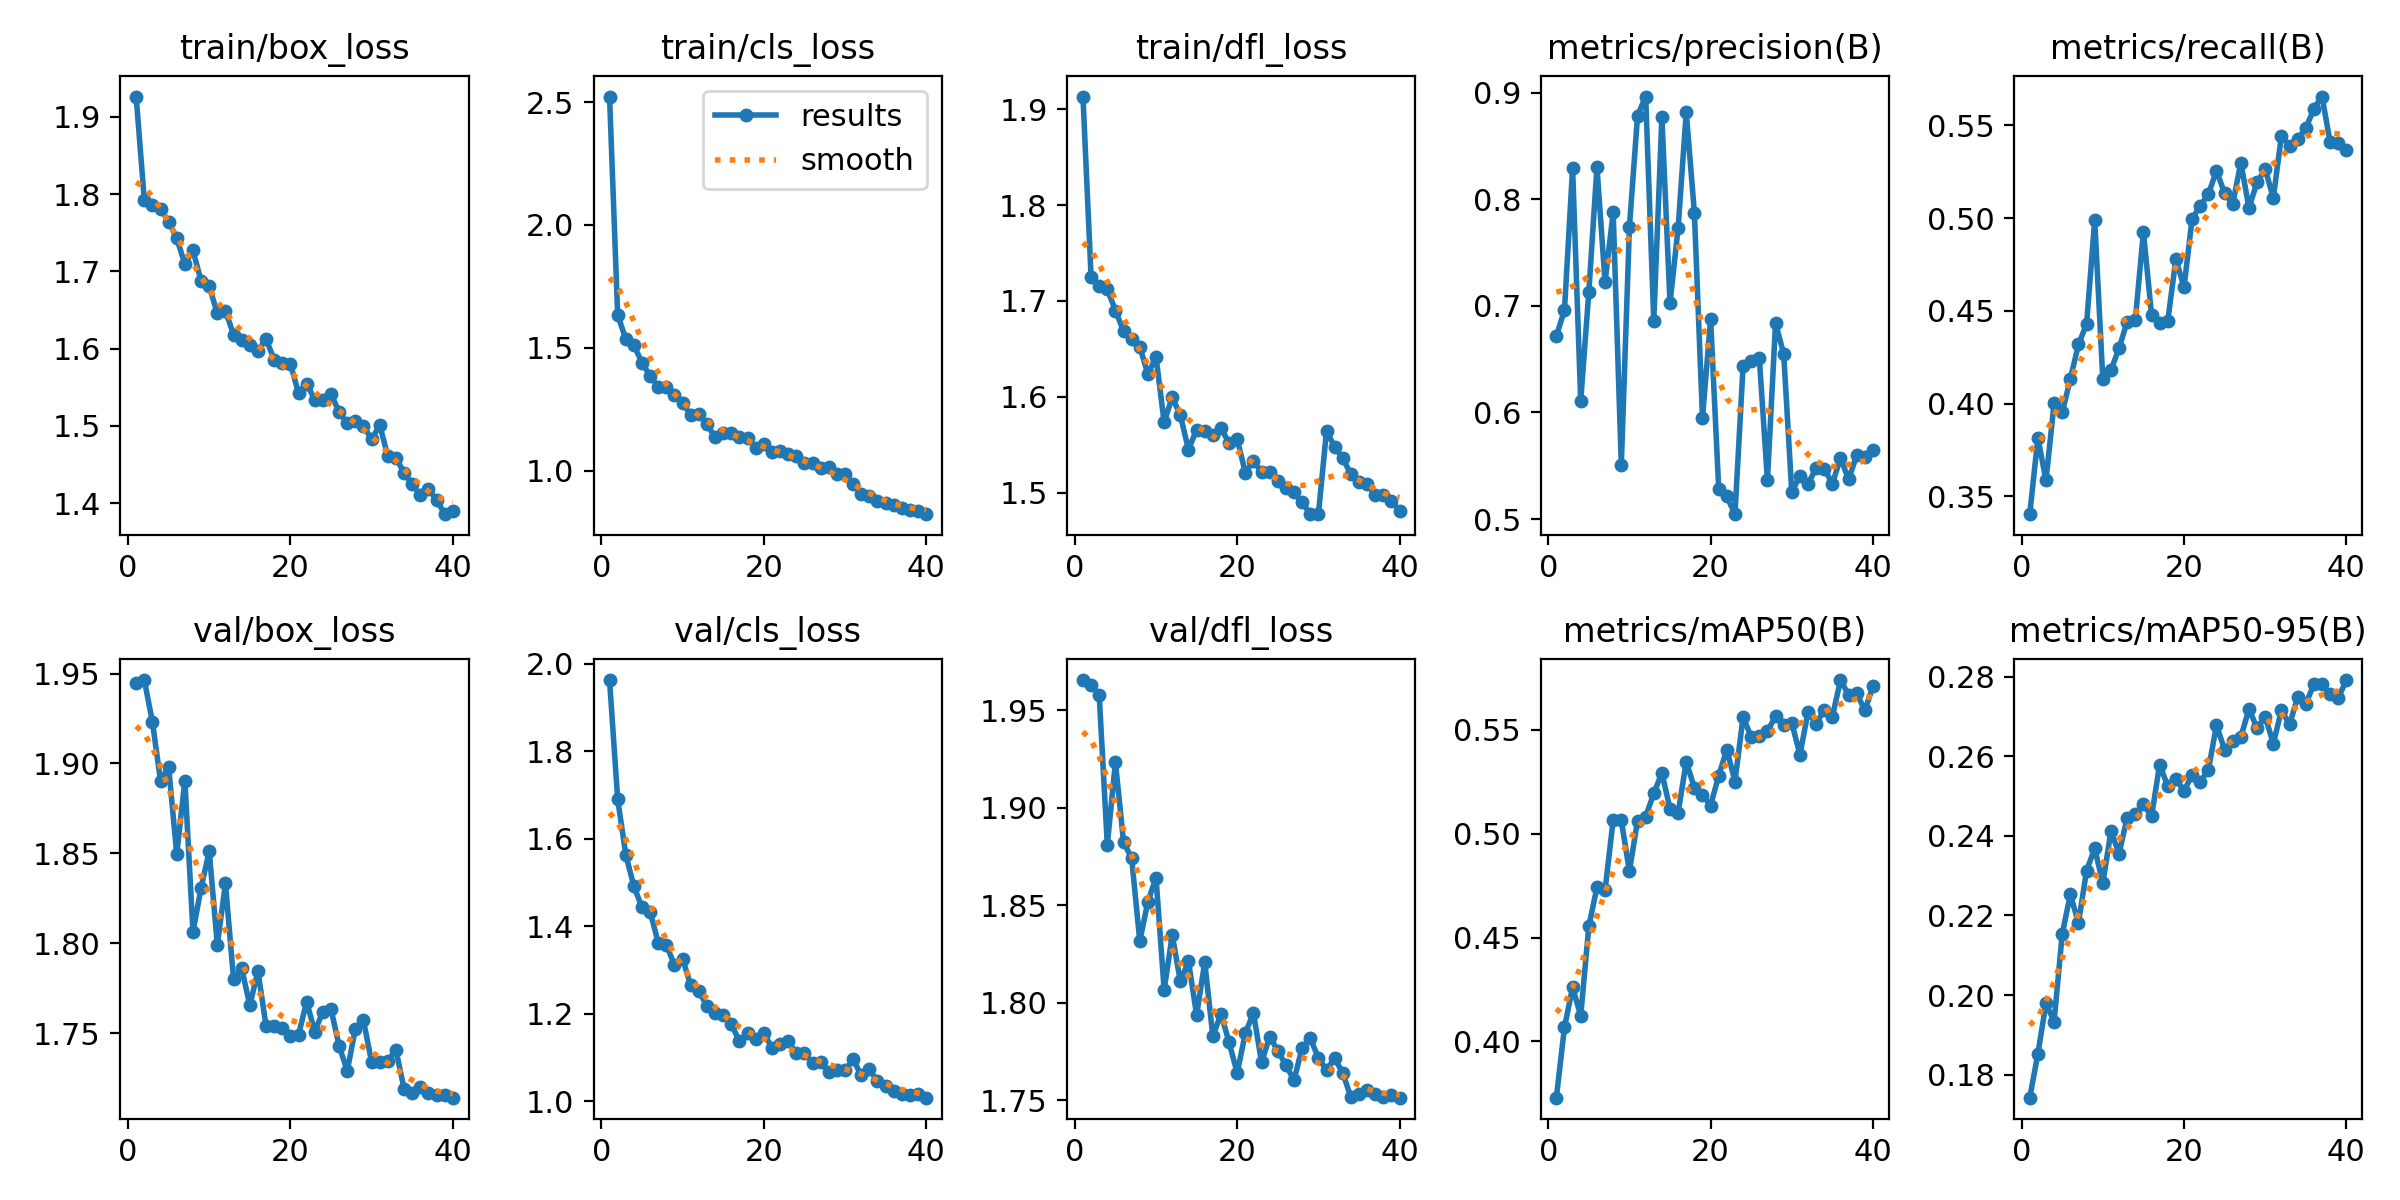


confusion_matrix.png


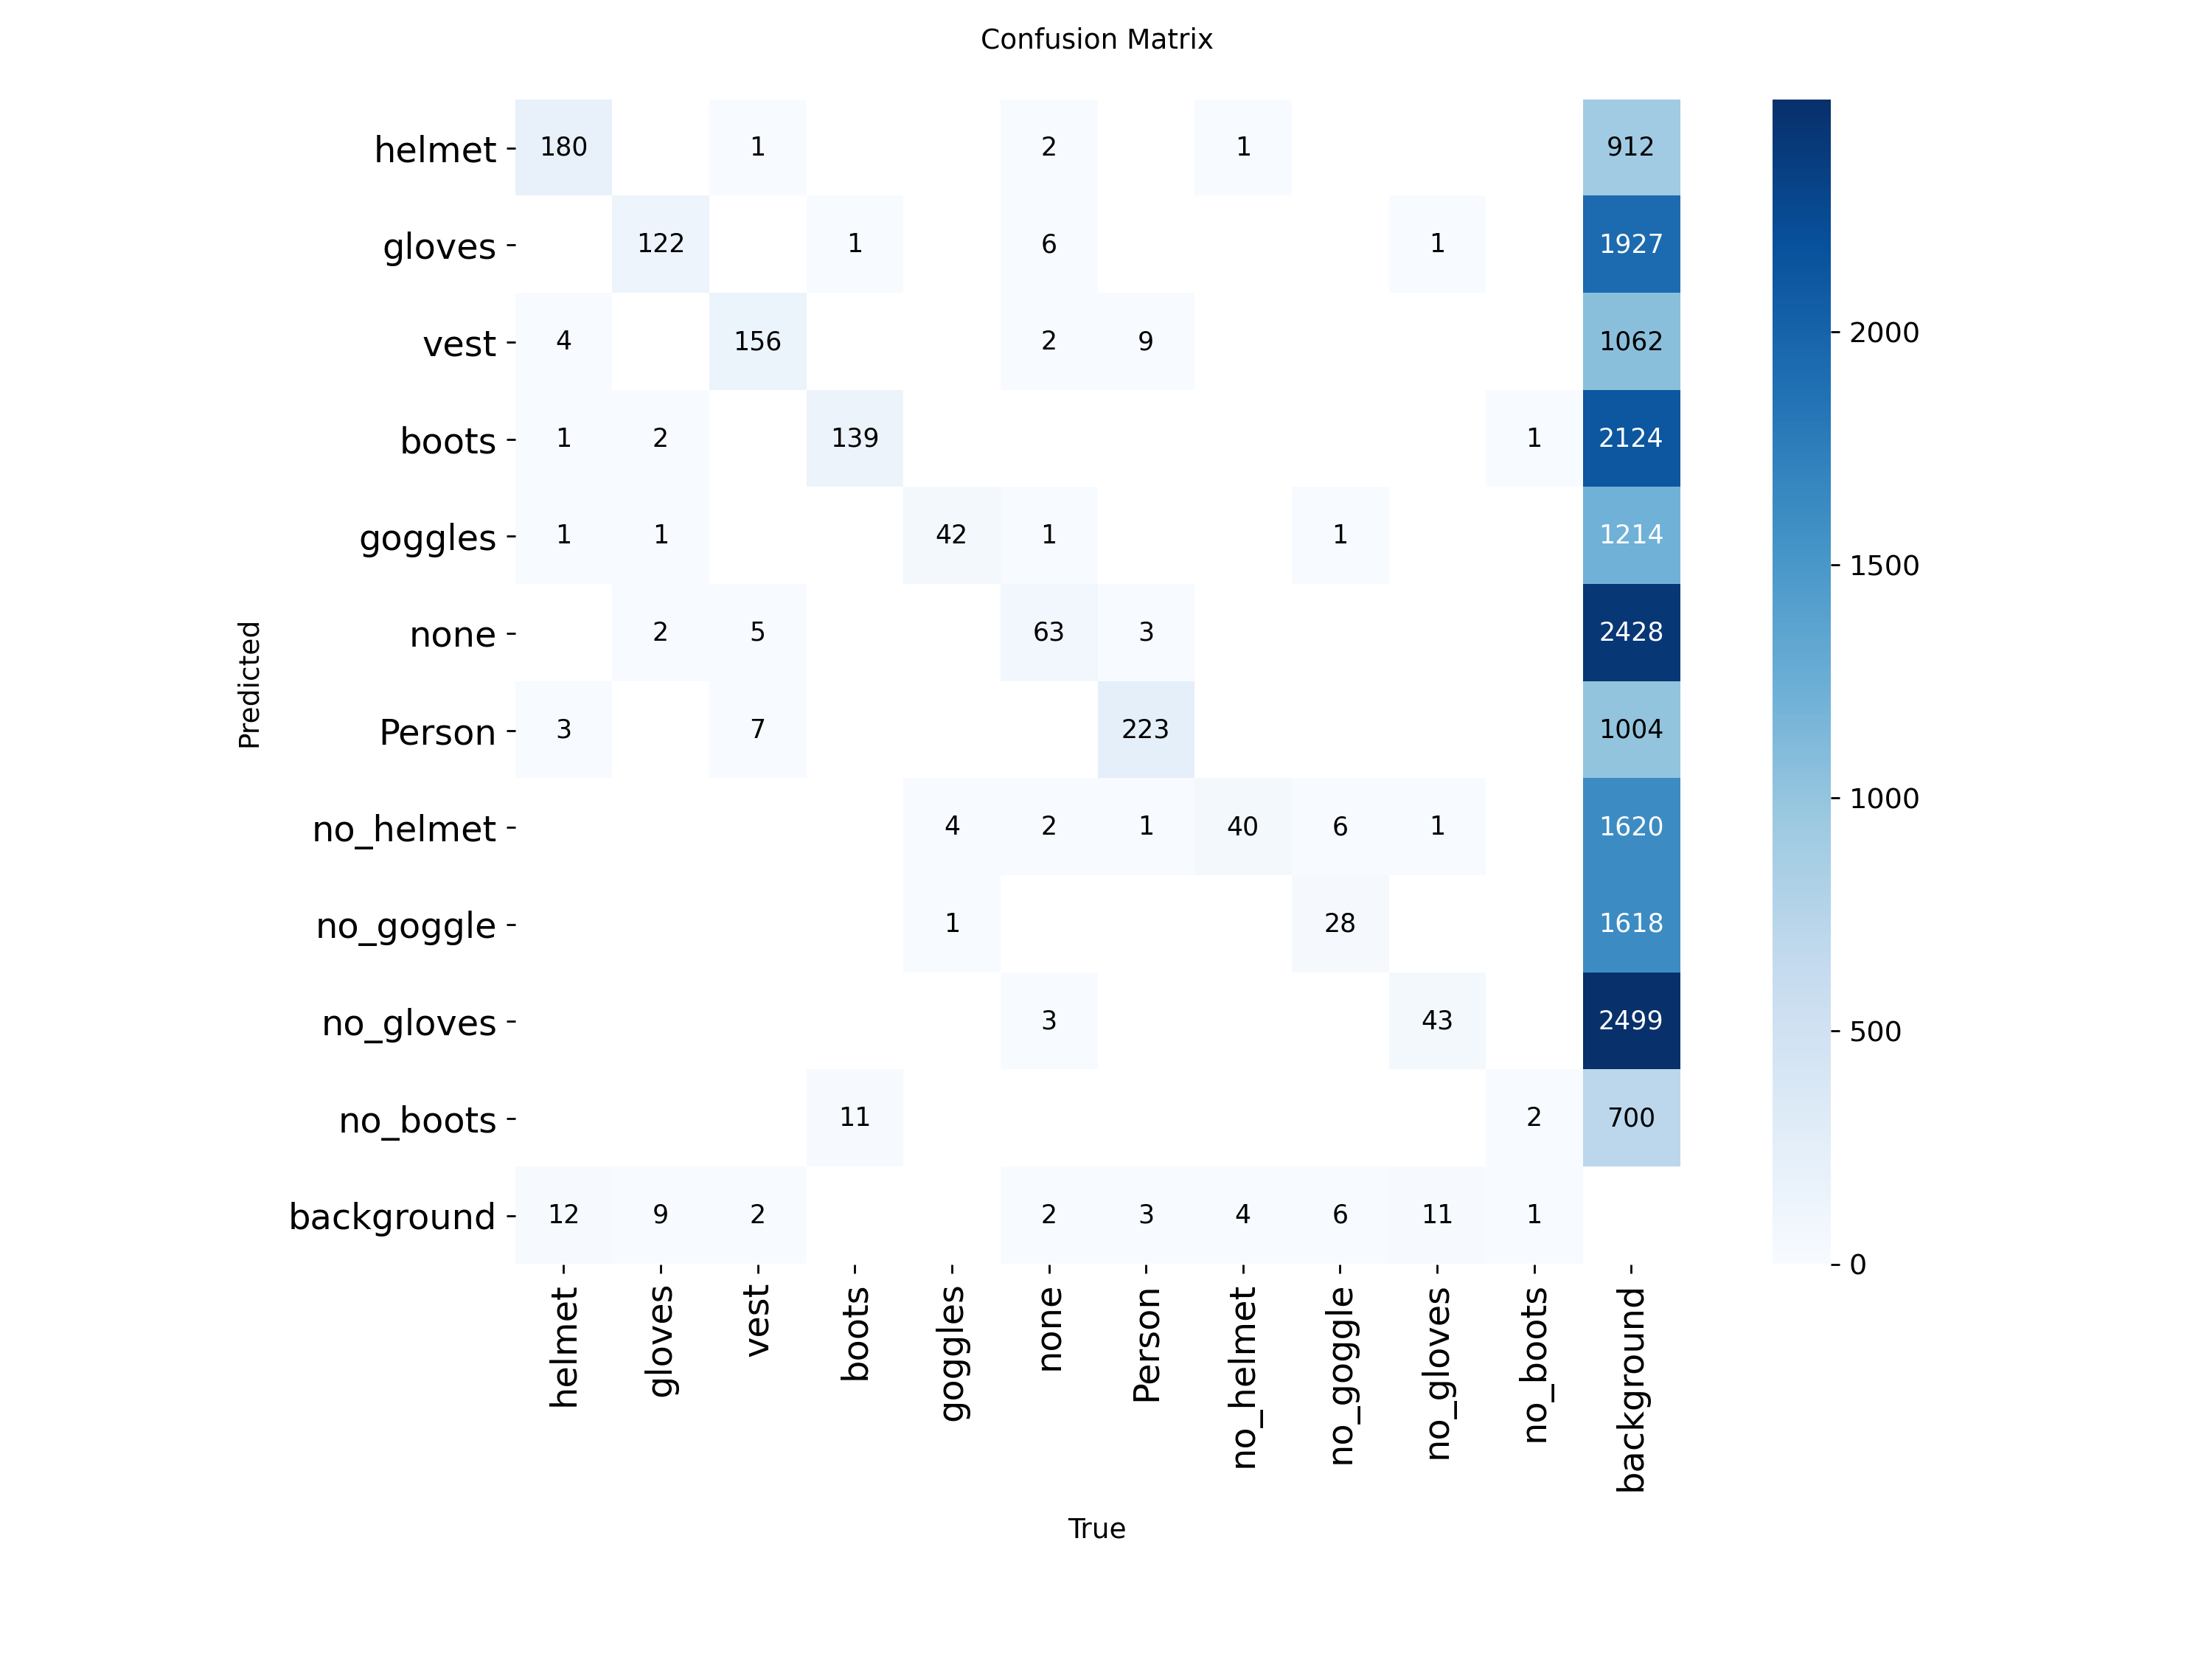


confusion_matrix_normalized.png


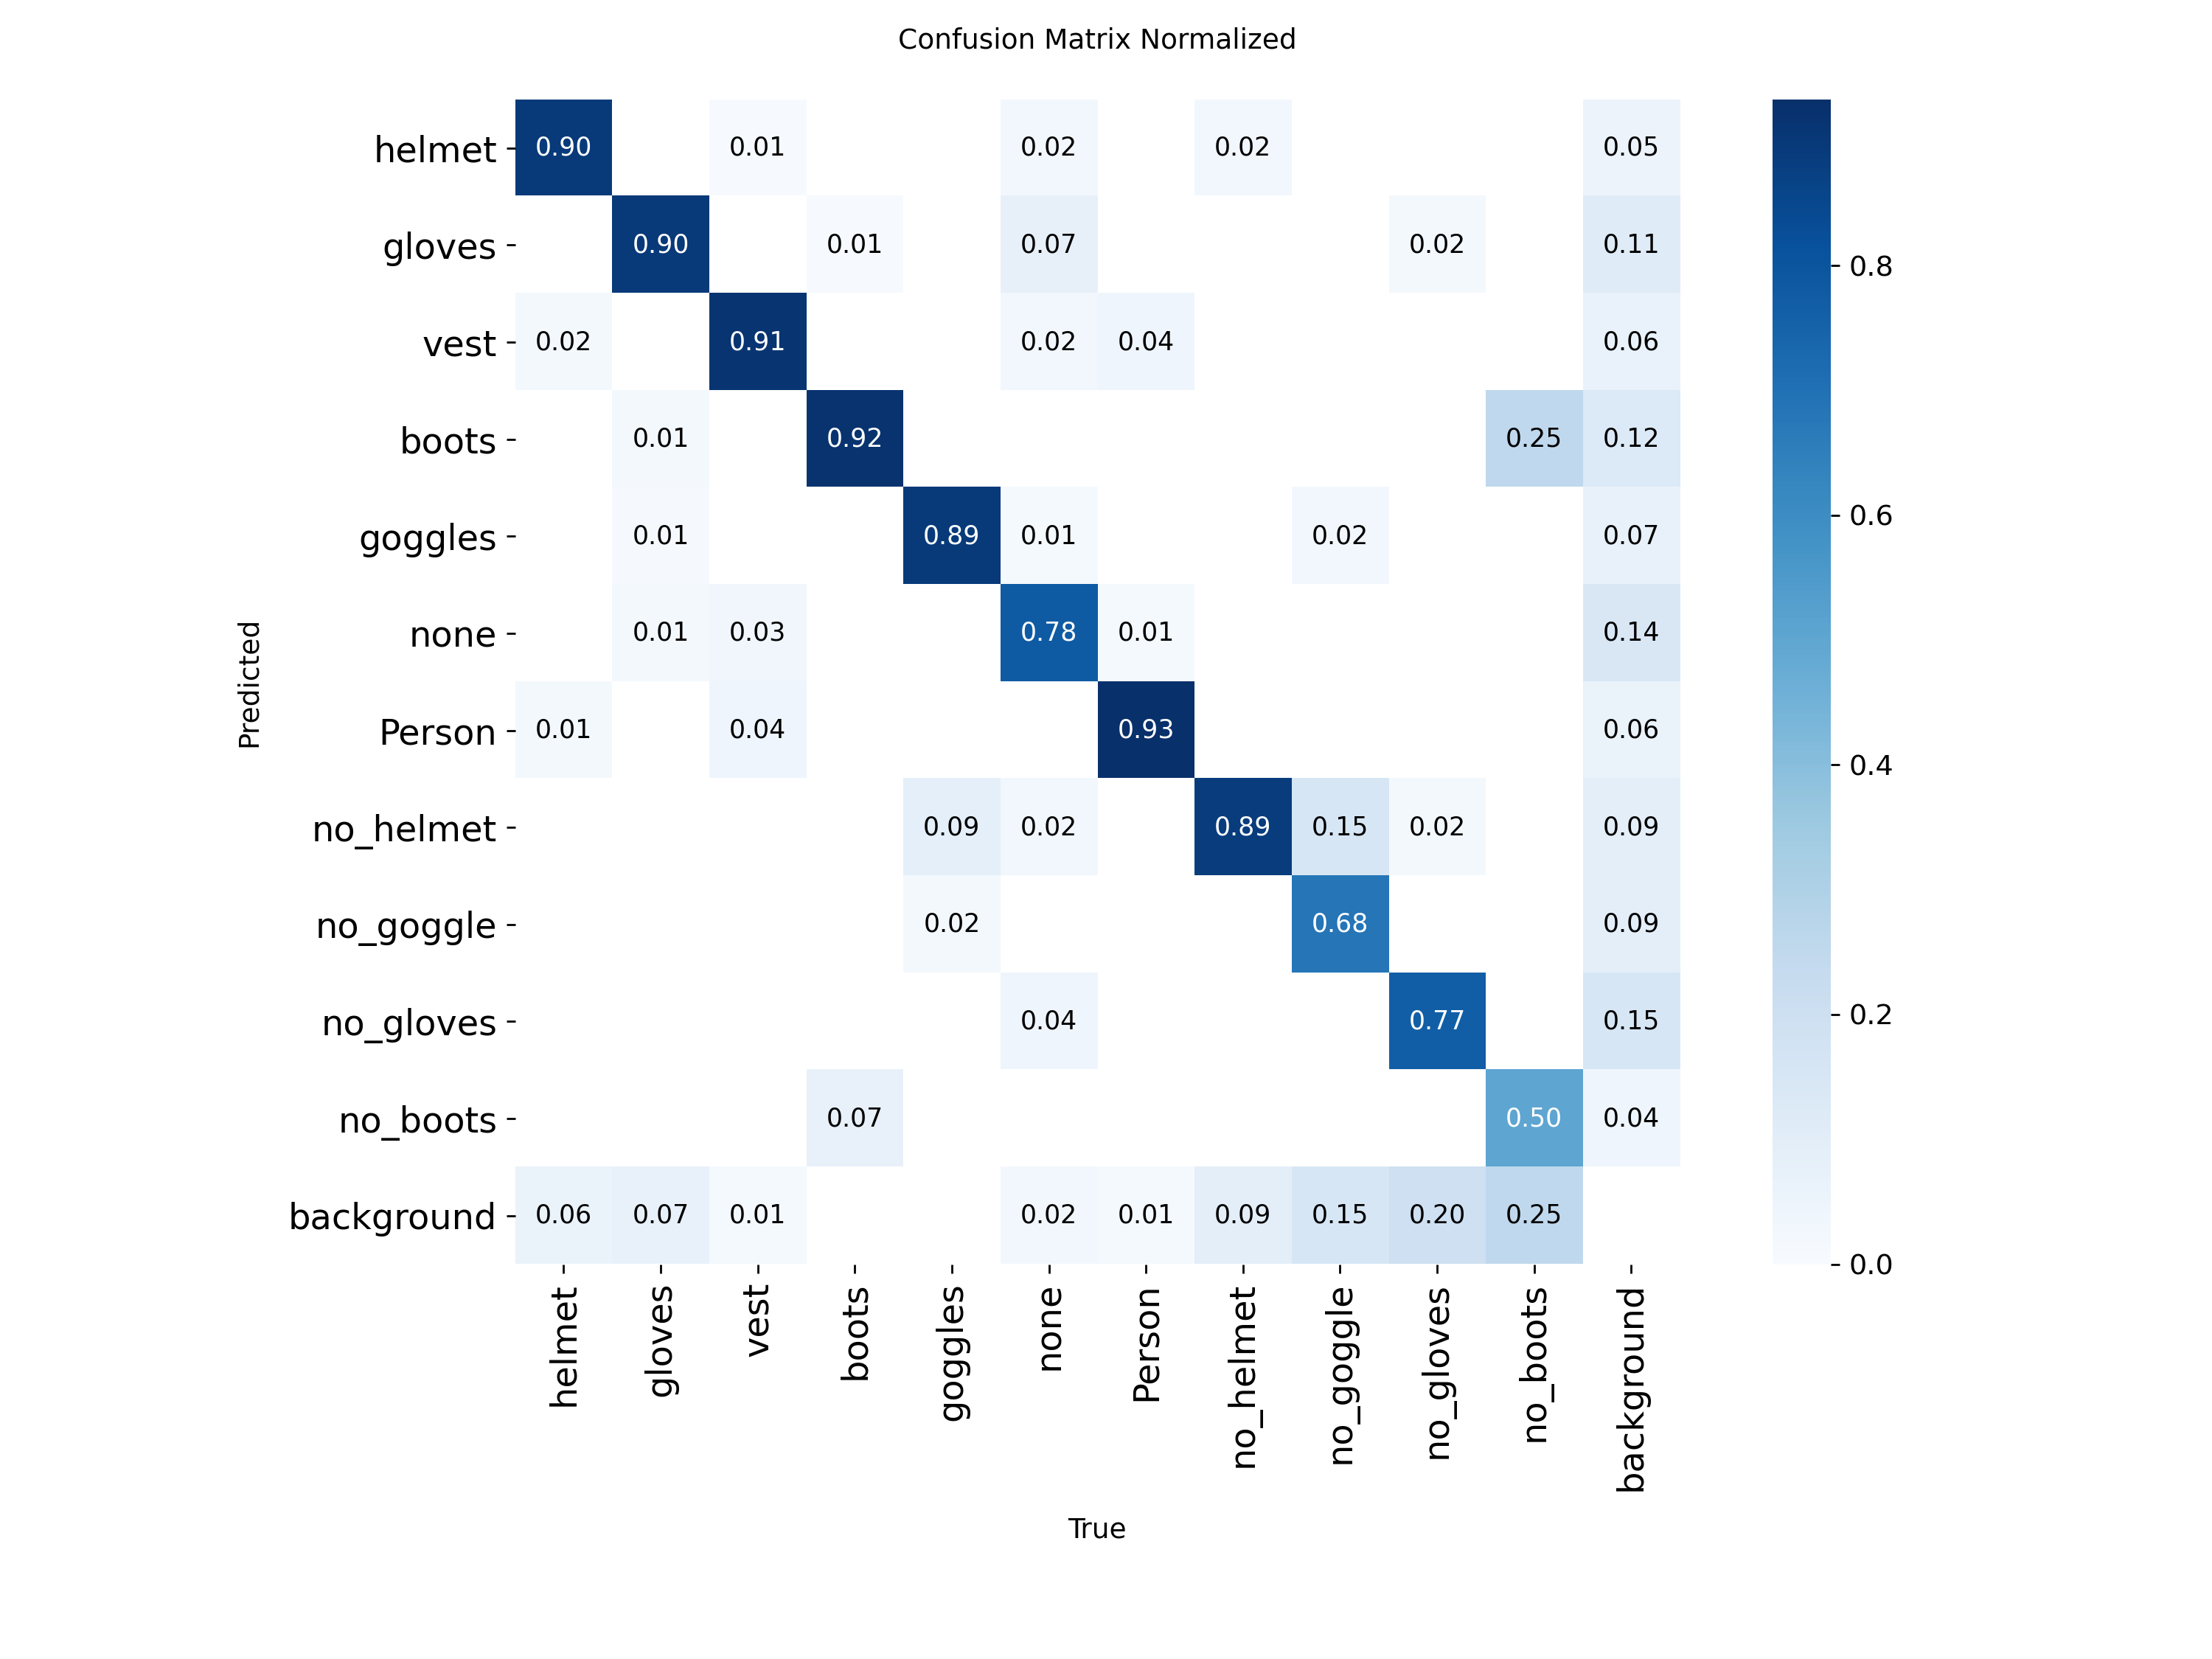


BoxPR_curve.png


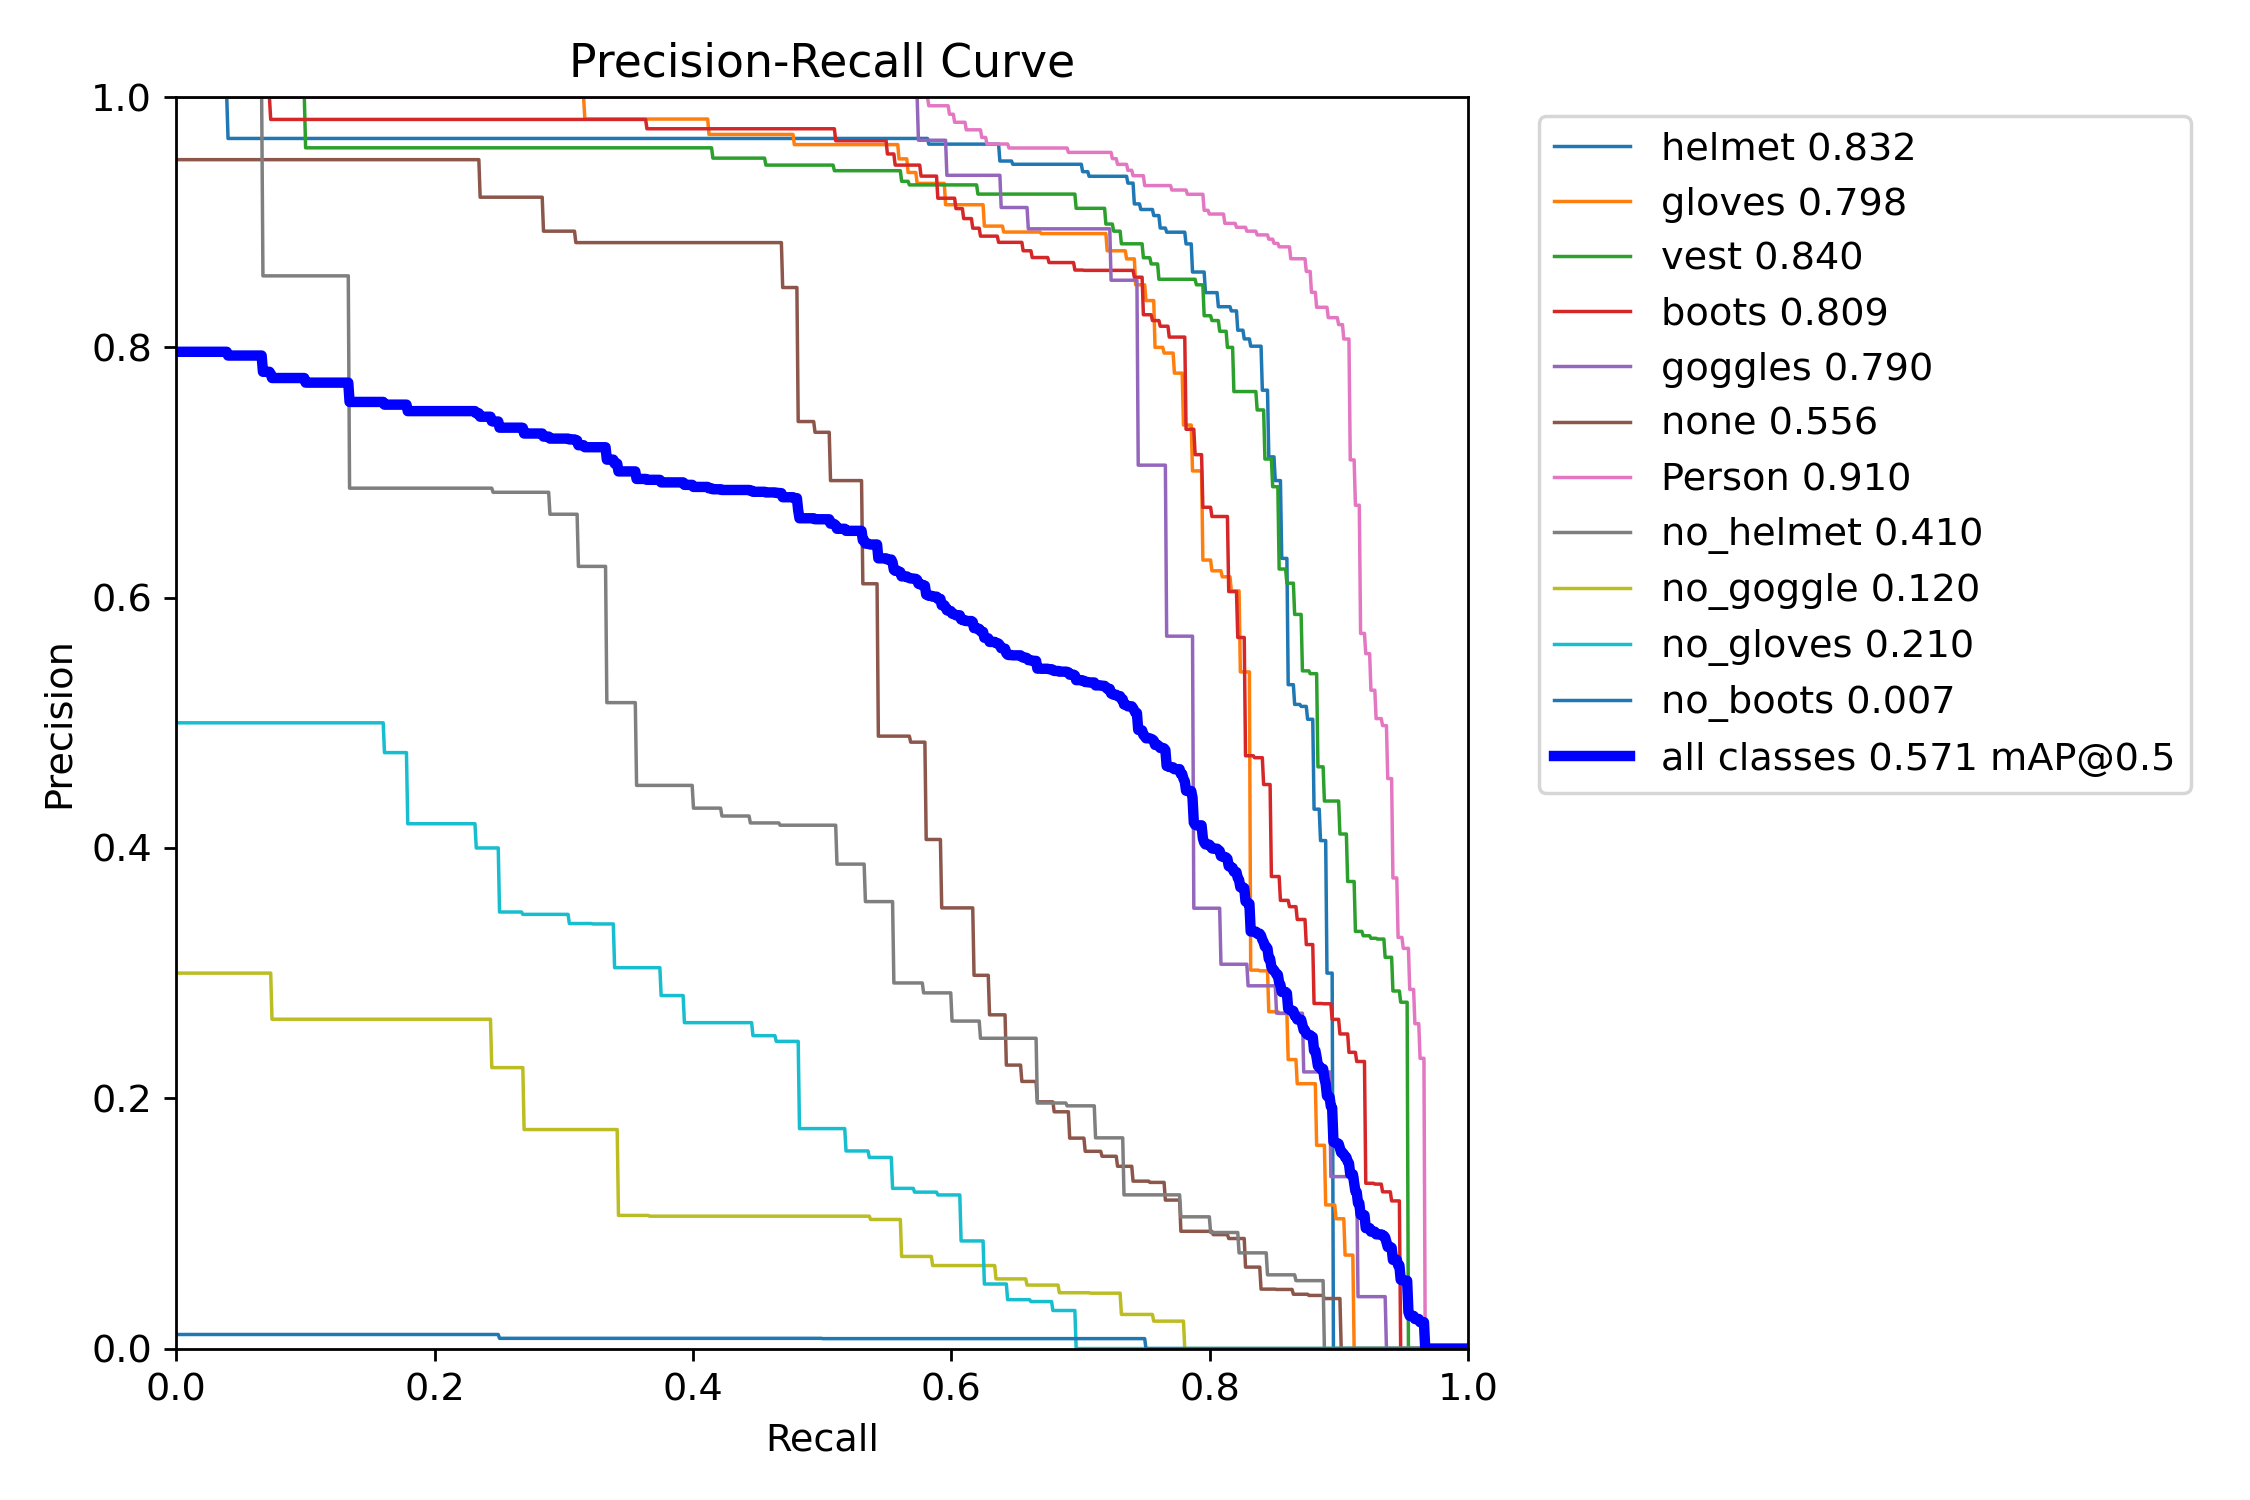


## improved_test

confusion_matrix.png


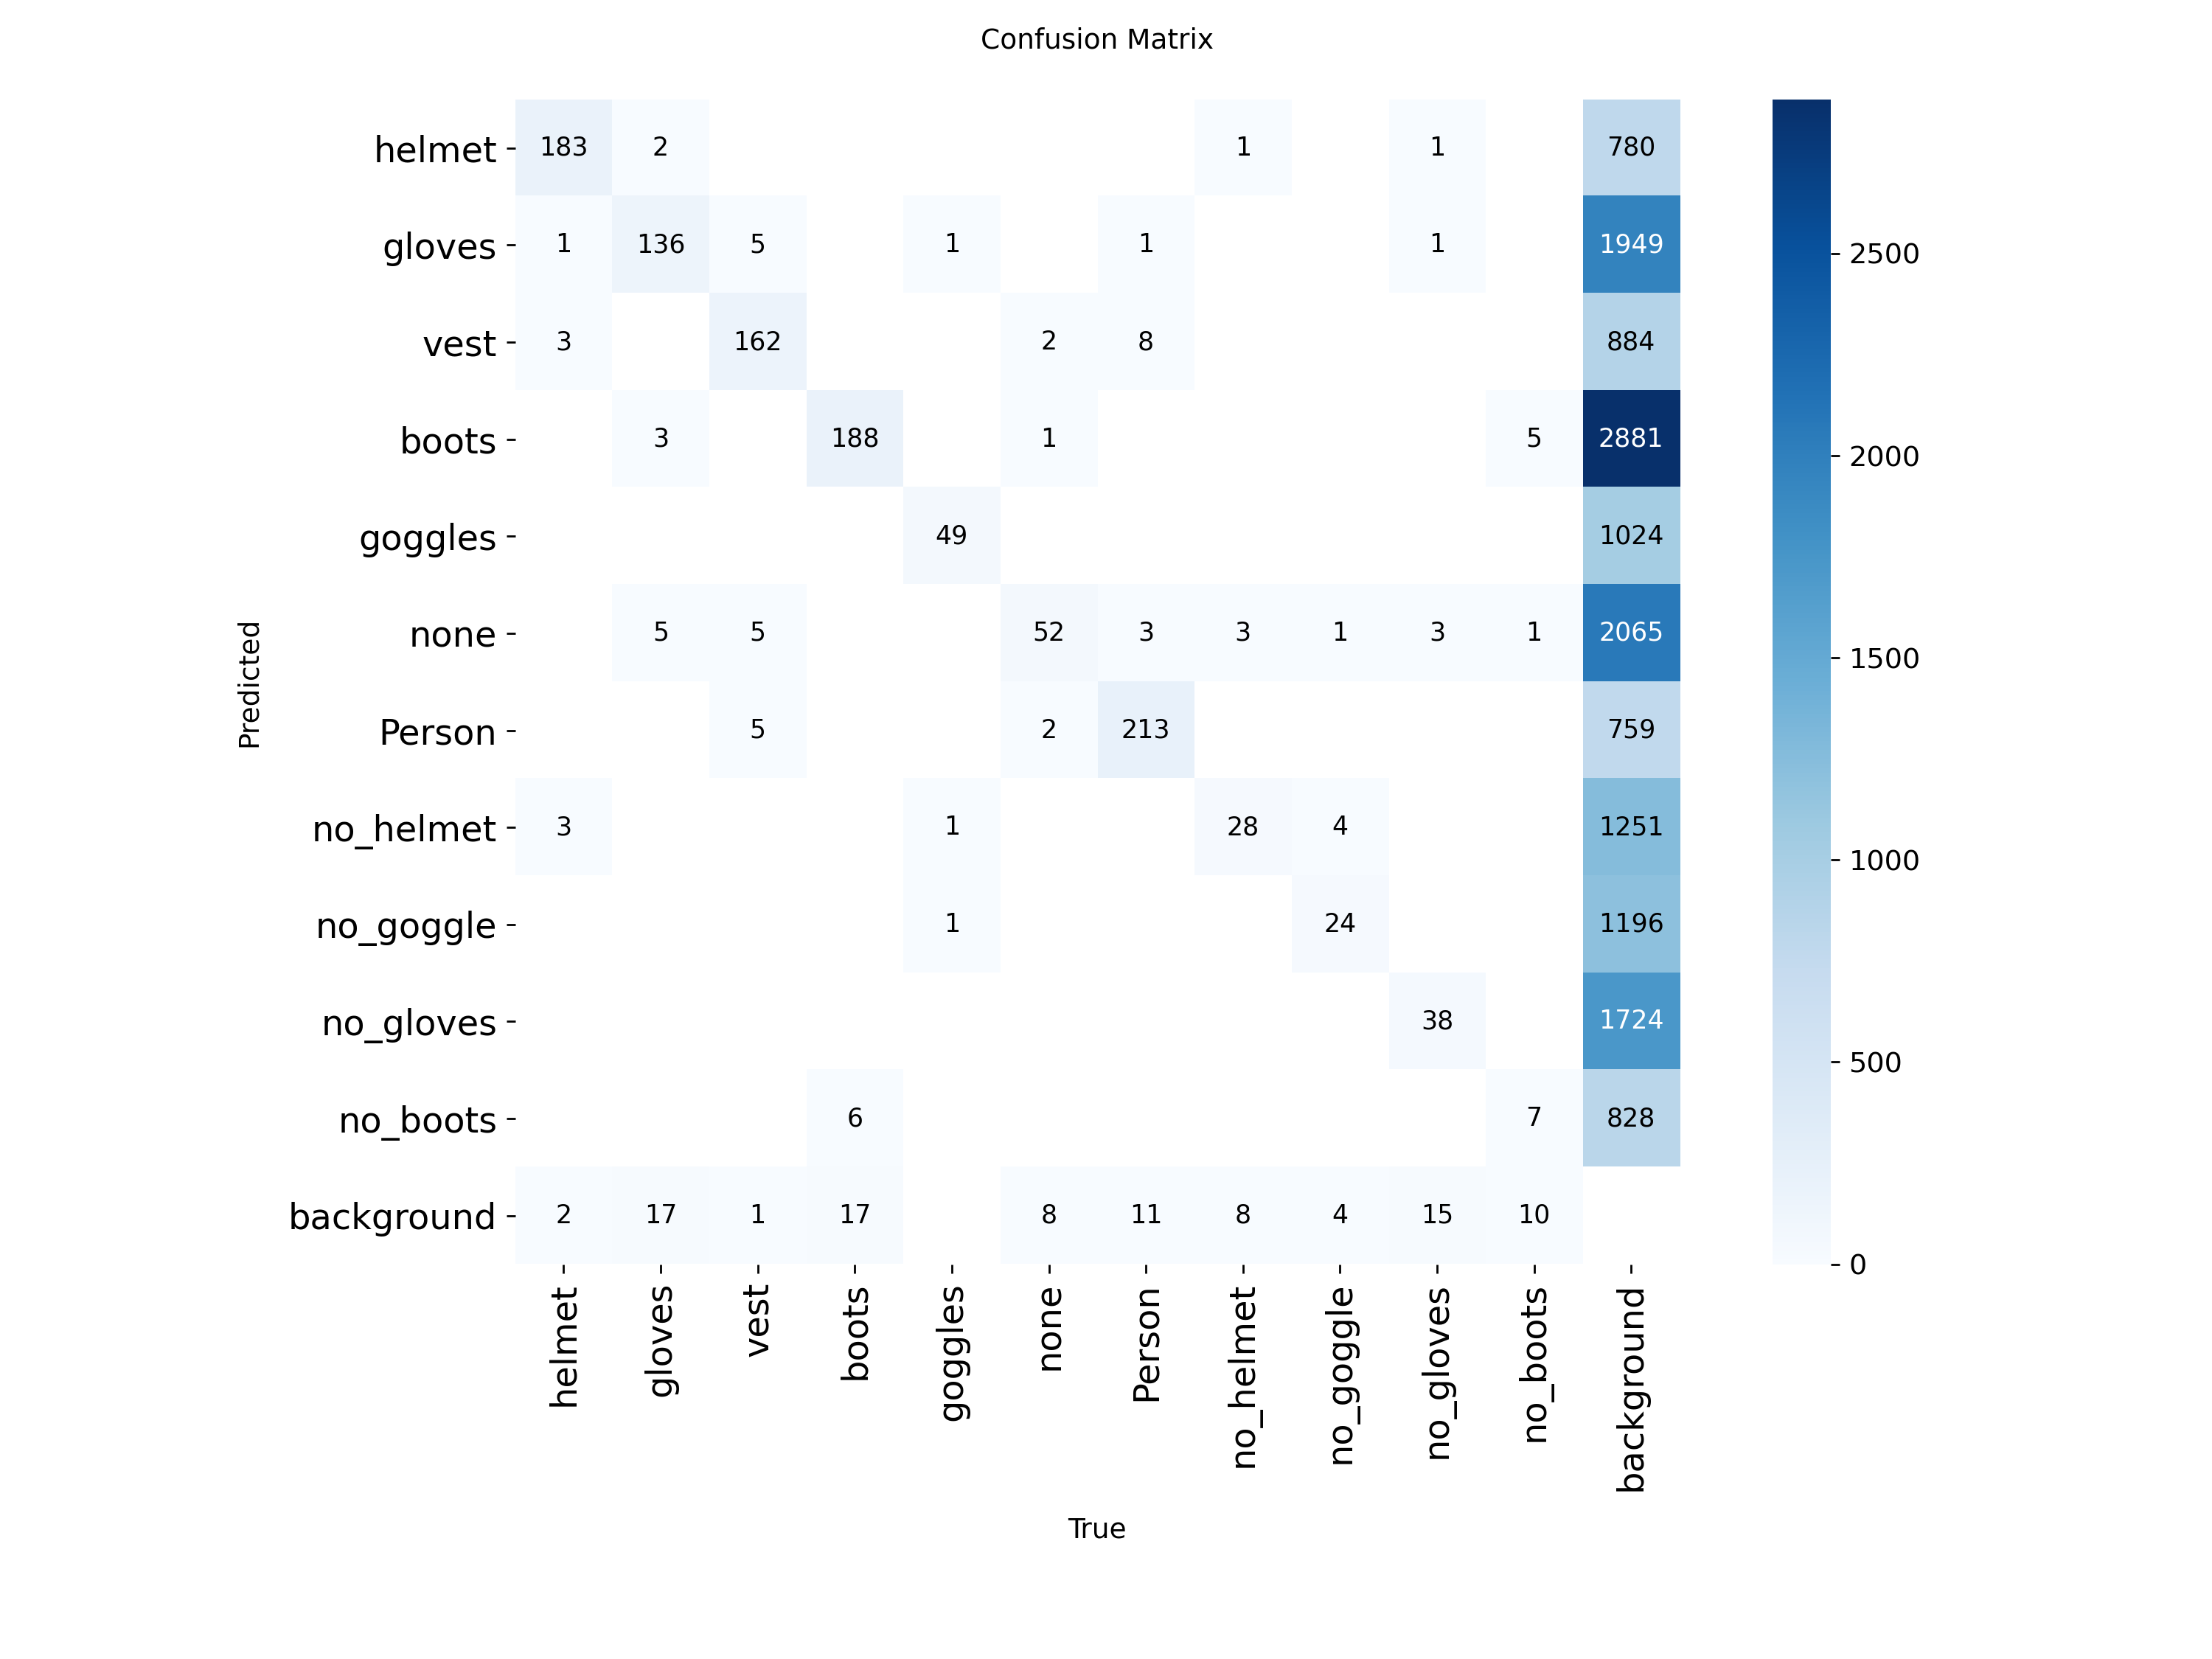


confusion_matrix_normalized.png


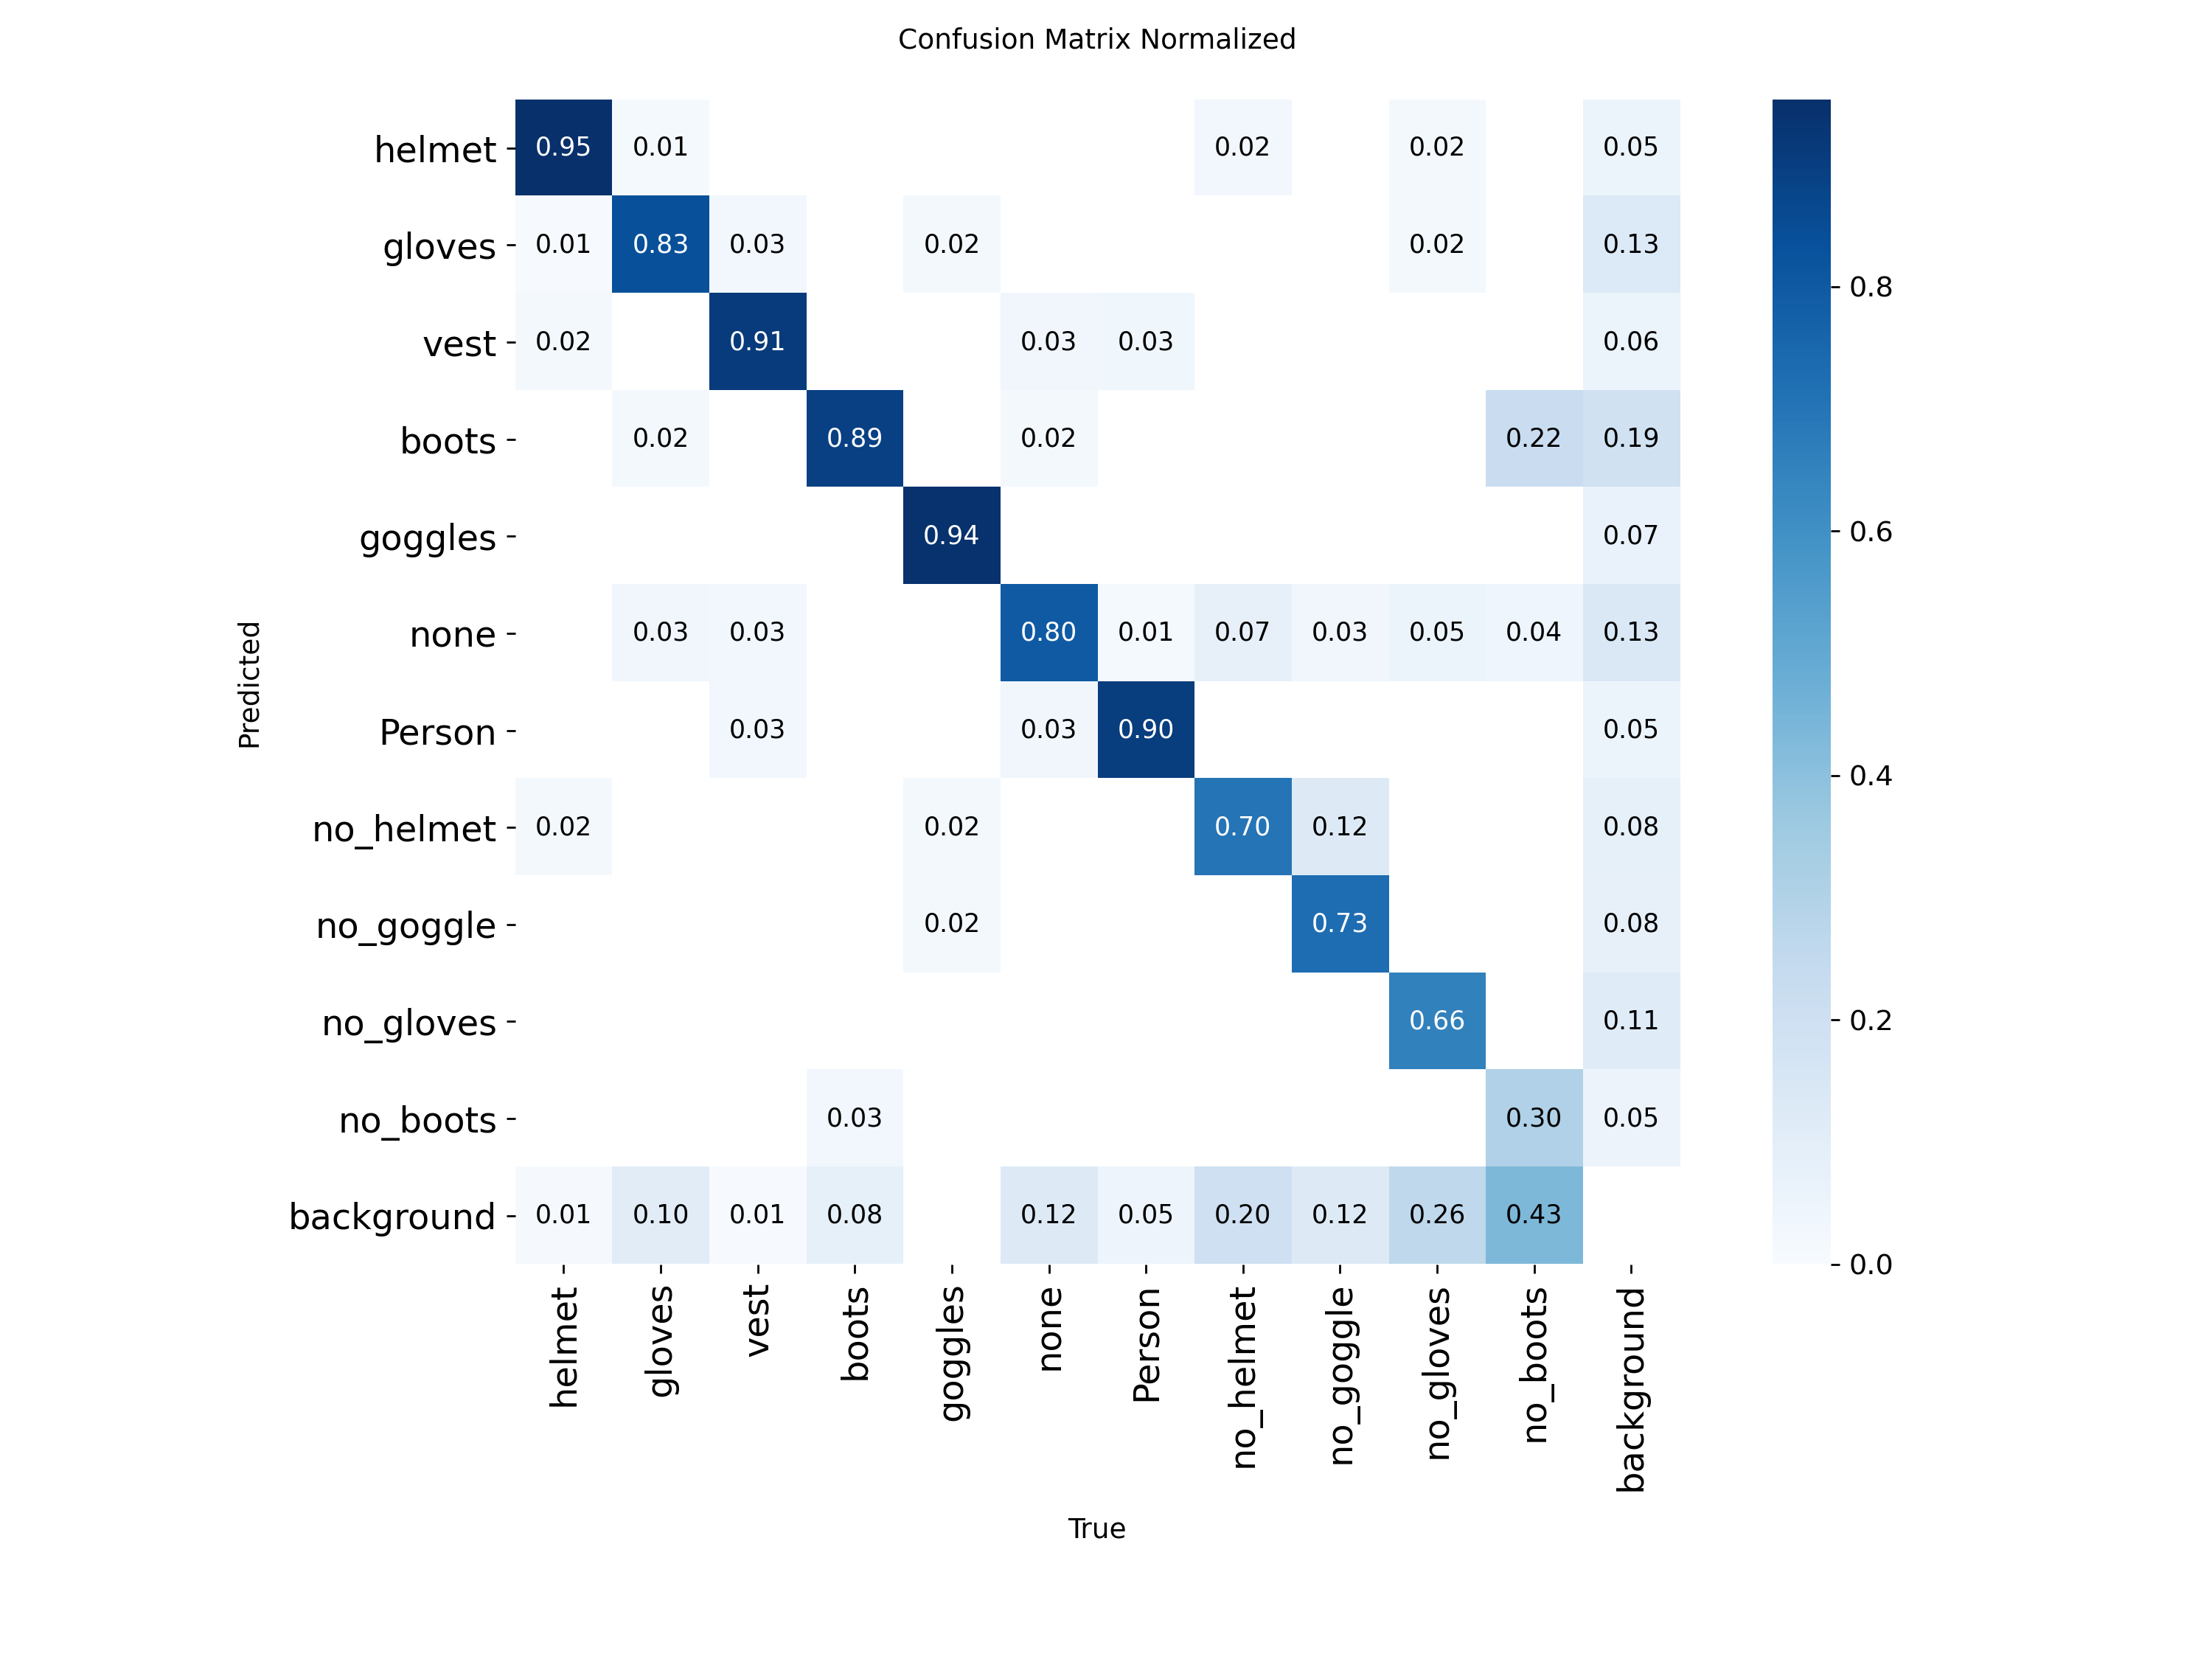


BoxPR_curve.png


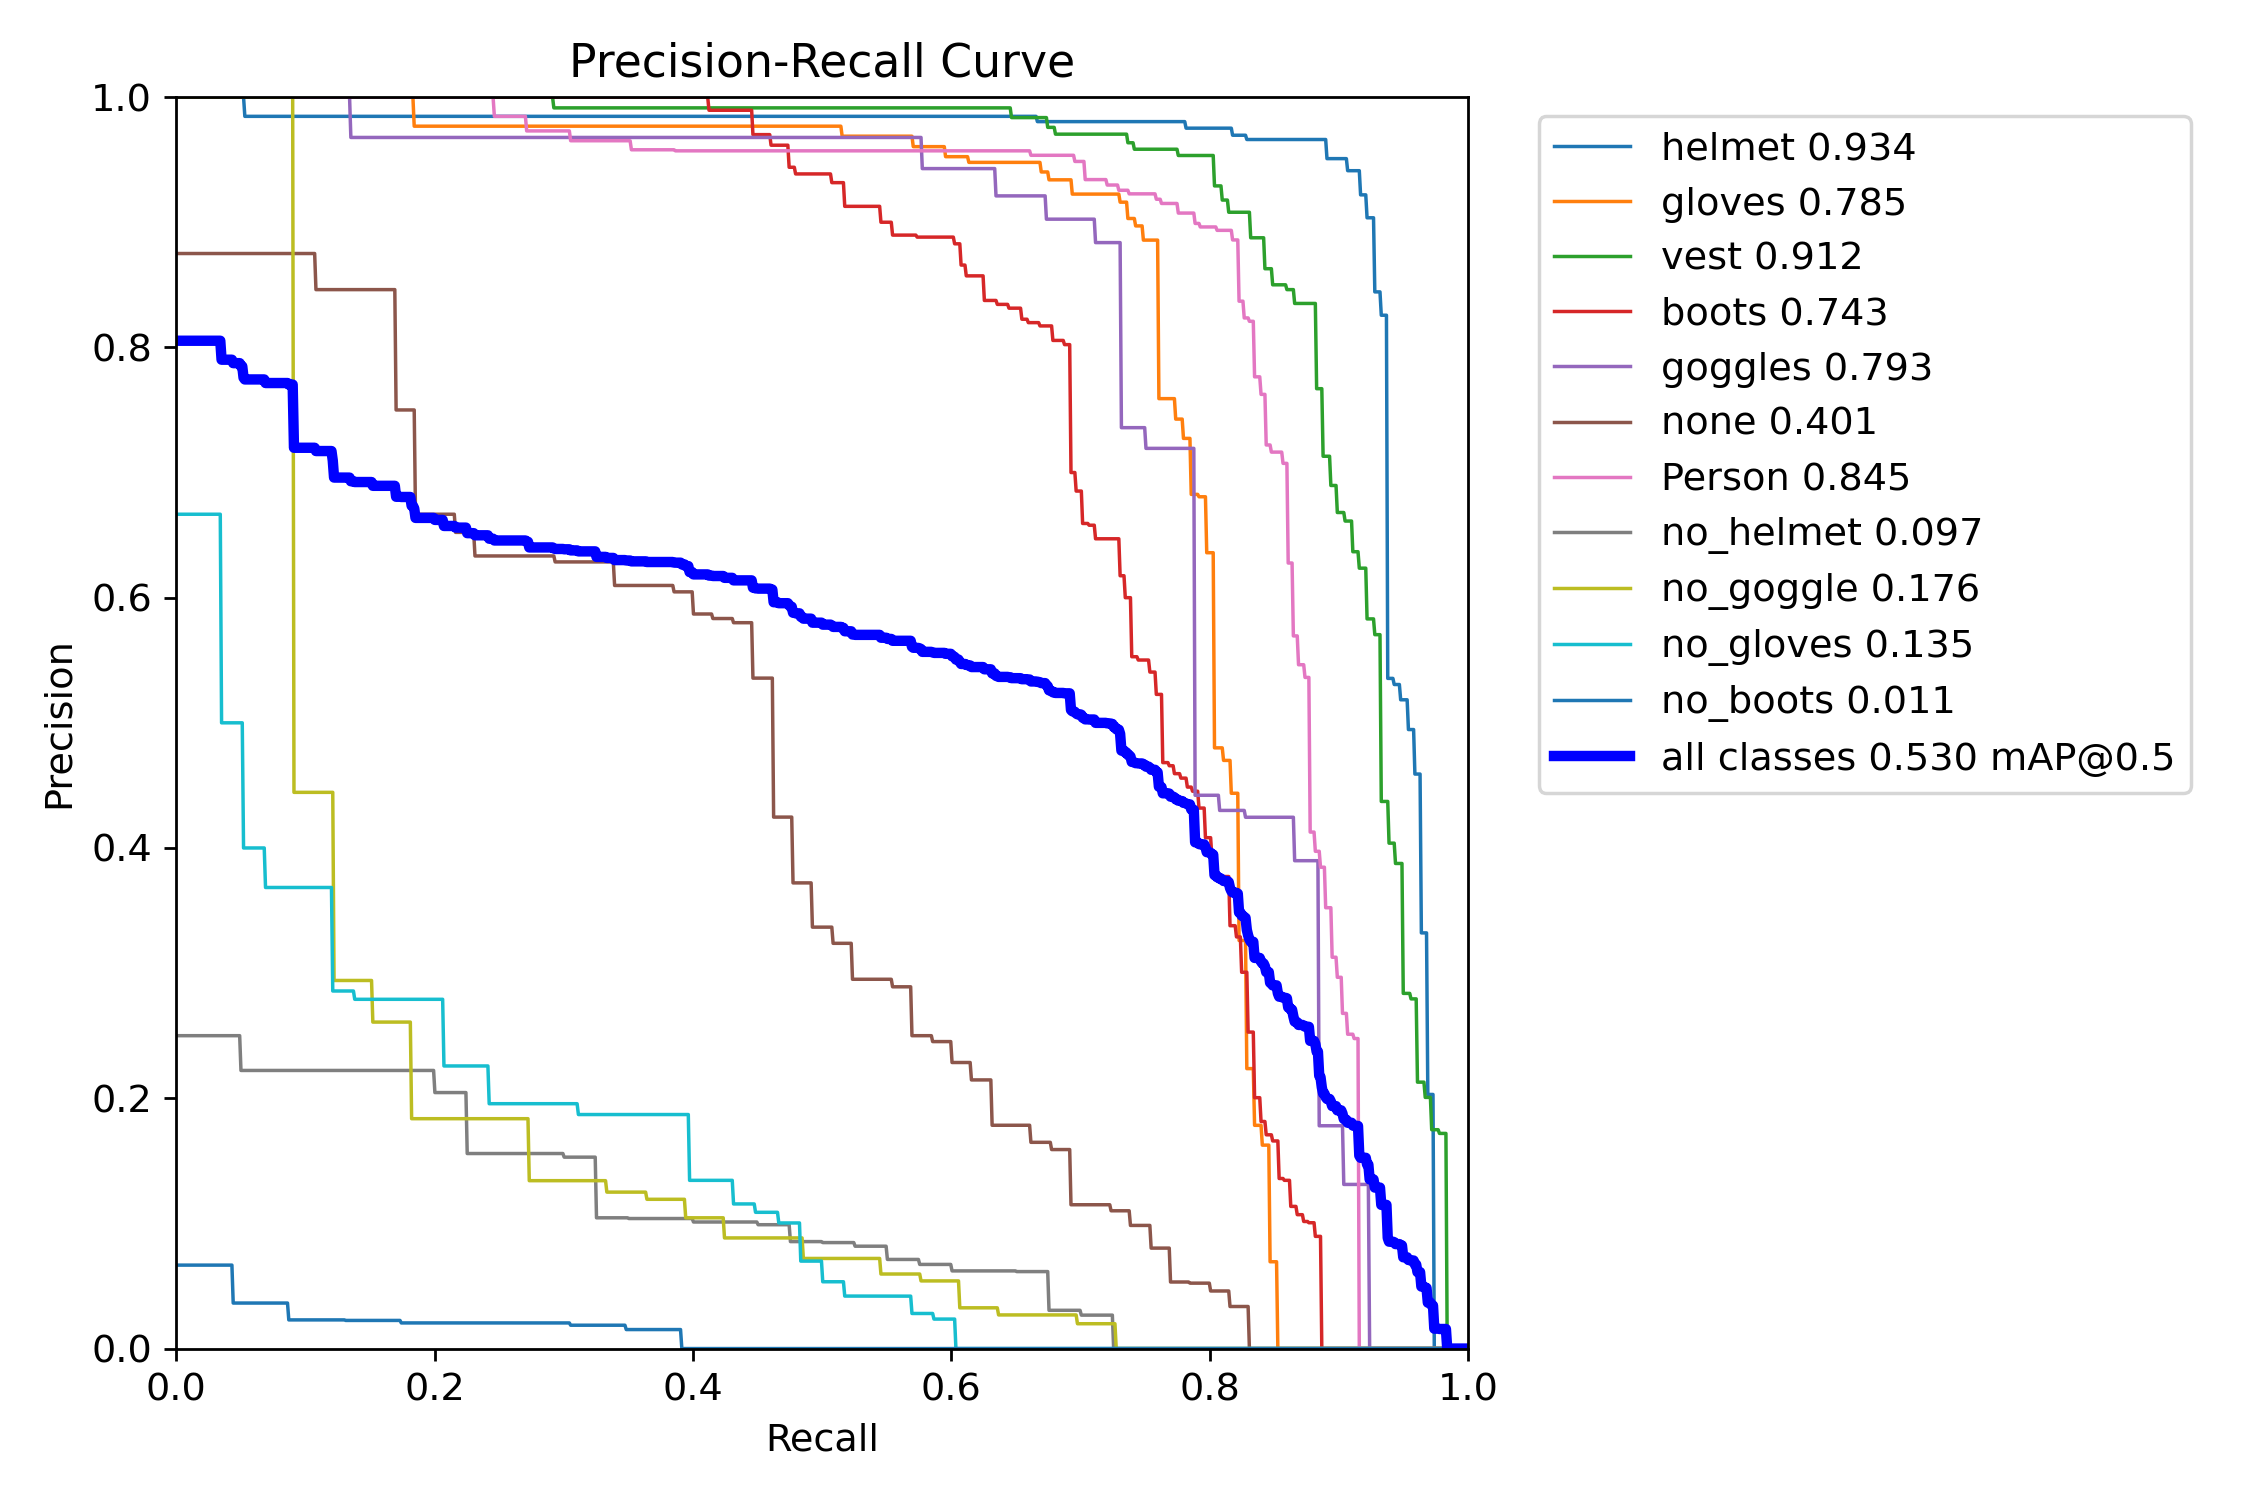

In [ ]:
from pathlib import Path
from IPython.display import display, Image

PROJECT_DIR = Path("/content/SmartBuildAI")

plot_names = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "BoxPR_curve.png",
]

for folder_name in ["improved_model", "improved_test"]:
    folder = PROJECT_DIR / folder_name
    print(f"\n## {folder_name}")

    for name in plot_names:
        matches = list(folder.rglob(name)) if folder.exists() else []
        for path in matches:
            print(f"\n{path.name}")
            display(Image(filename=str(path), width=650))

## 15. Generate the Safety Detection Report

In [ ]:
import cv2
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/SmartBuildAI")
VIDEO_PATH = Path("/content/construction.mp4")
MODEL_PATH = PROJECT_DIR / "improved_model/weights/best.pt"

model = YOLO(str(MODEL_PATH))
cap = cv2.VideoCapture(str(VIDEO_PATH))

fps = cap.get(cv2.CAP_PROP_FPS) or 25
frame_no = 0
records = []

while True:
    ok, frame = cap.read()
    if not ok:
        break

    # Sample approximately one frame per second
    if frame_no % max(1, round(fps)) == 0:
        result = model.predict(
            frame,
            imgsz=416,
            conf=0.35,
            device="cpu",
            verbose=False
        )[0]

        timestamp = frame_no / fps

        for box in result.boxes:
            class_id = int(box.cls[0])
            records.append({
                "Timestamp_seconds": round(timestamp, 2),
                "Detected_class": model.names[class_id],
                "Confidence": round(float(box.conf[0]), 3)
            })

    frame_no += 1

cap.release()

report = pd.DataFrame(
    records,
    columns=["Timestamp_seconds", "Detected_class", "Confidence"]
)

csv_path = PROJECT_DIR / "safety_detection_report.csv"
report.to_csv(csv_path, index=False)

print("Frames sampled:", len(range(0, frame_no, max(1, round(fps)))))
print("Detections recorded:", len(report))
display(report.head(20))
print("Report saved to:", csv_path)

Frames sampled: 30
Detections recorded: 141


,Timestamp_seconds,Detected_class,Confidence
0,0.0,Person,0.641
1,0.0,vest,0.528
2,0.0,vest,0.480
3,0.0,helmet,0.403
4,0.0,vest,0.398
5,1.0,Person,0.711
6,1.0,vest,0.648
7,1.0,helmet,0.520
8,1.0,vest,0.432
9,2.0,vest,0.731


Report saved to: /content/SmartBuildAI/safety_detection_report.csv


## 16. Visualize Detection Results

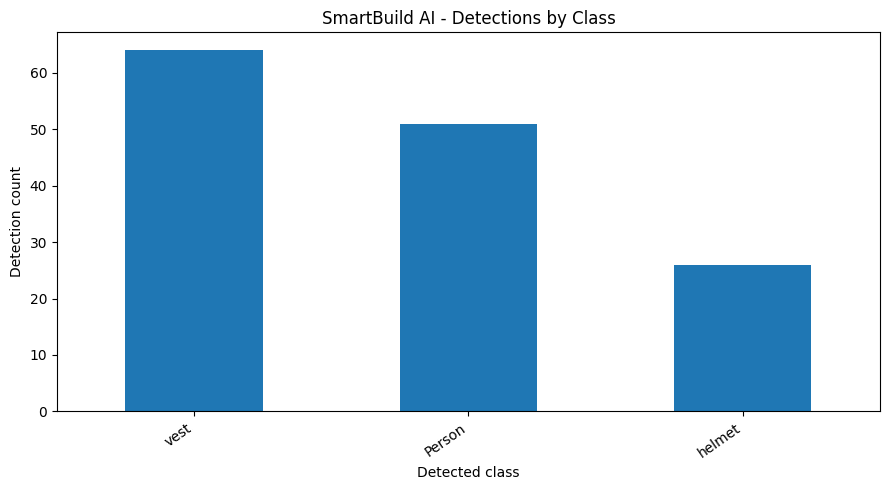

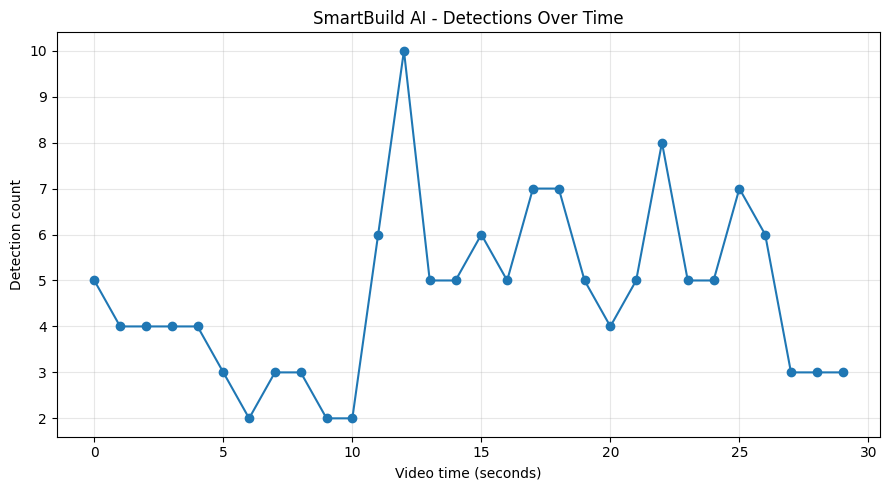

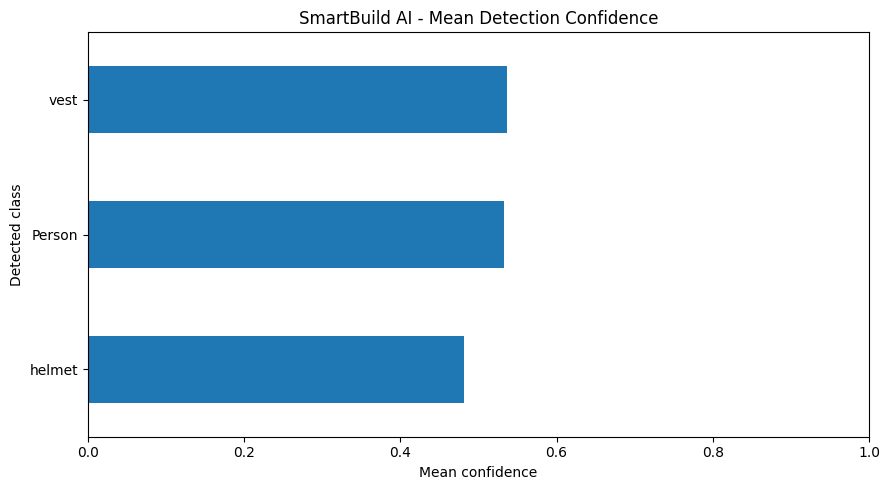

,Detection_count,Mean_confidence
Detected_class,,
Person,51,0.533
helmet,26,0.482
vest,64,0.536


All three figures saved in: /content/SmartBuildAI


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

PROJECT_DIR = Path("/content/SmartBuildAI")
report = pd.read_csv(PROJECT_DIR / "safety_detection_report.csv")

# Figure 1: Number of detections per class
plt.figure(figsize=(9, 5))
report["Detected_class"].value_counts().plot(kind="bar")
plt.title("SmartBuild AI - Detections by Class")
plt.xlabel("Detected class")
plt.ylabel("Detection count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "detections_by_class.png", dpi=300)
plt.show()

# Figure 2: Detections over time
counts = report.groupby("Timestamp_seconds").size()
plt.figure(figsize=(9, 5))
counts.plot(marker="o")
plt.title("SmartBuild AI - Detections Over Time")
plt.xlabel("Video time (seconds)")
plt.ylabel("Detection count")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "detections_over_time.png", dpi=300)
plt.show()

# Figure 3: Average confidence by class
avg = report.groupby("Detected_class")["Confidence"].mean().sort_values()
plt.figure(figsize=(9, 5))
avg.plot(kind="barh")
plt.title("SmartBuild AI - Mean Detection Confidence")
plt.xlabel("Mean confidence")
plt.ylabel("Detected class")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "average_confidence.png", dpi=300)
plt.show()

# Summary table
summary = report.groupby("Detected_class").agg(
    Detection_count=("Detected_class", "size"),
    Mean_confidence=("Confidence", "mean")
).round(3)

display(summary)
print("All three figures saved in:", PROJECT_DIR)

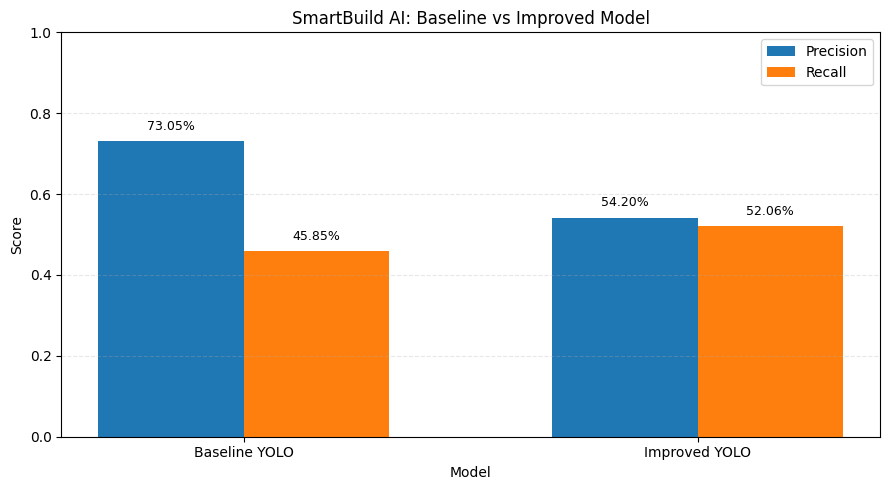

Graph saved to: /content/SmartBuildAI/precision_recall_comparison.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Actual test-set evaluation results
models = ["Baseline YOLO", "Improved YOLO"]

precision = [0.7305, 0.5420]
recall = [0.4585, 0.5206]

x = np.arange(len(models))
width = 0.32

plt.figure(figsize=(9, 5))

bars1 = plt.bar(
    x - width/2, precision, width,
    label="Precision"
)
bars2 = plt.bar(
    x + width/2, recall, width,
    label="Recall"
)

plt.title("SmartBuild AI: Baseline vs Improved Model")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.2%}",
            ha="center", va="bottom", fontsize=9
        )

plt.tight_layout()

output = Path("/content/SmartBuildAI")
output.mkdir(parents=True, exist_ok=True)
plt.savefig(output / "precision_recall_comparison.png", dpi=300)
plt.show()

print("Graph saved to:", output / "precision_recall_comparison.png")


In [ ]:

from ultralytics import YOLO
from pathlib import Path

PROJECT_DIR = Path("/content/SmartBuildAI")

DATA_YAML = "https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml"

model = YOLO(str(
    PROJECT_DIR / "improved_model/weights/best.pt"
))

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    plots=True,
    device="cpu",
    project=str(PROJECT_DIR),
    name="improved_test_plots"
)

print("Test evaluation completed.")
print("Plots saved in:", PROJECT_DIR / "improved_test_plots")


Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,135,137 parameters, 0 gradients, 8.7 GFLOPs
Found https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml locally at construction-ppe.yaml
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 57.7±14.1 MB/s, size: 136.4 KB)
val: Scanning /content/datasets/construction-ppe/labels/test.cache... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 17.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.7s/it 24.0s
                   all        141       1251      0.542      0.521       0.53      0.263
                helmet        110        192      0.903      0.922      0.934      0.495
                gloves         75        163      0.767      0.761      0.785      0.391
                  vest        111        178      0.764     

confusion_matrix.png


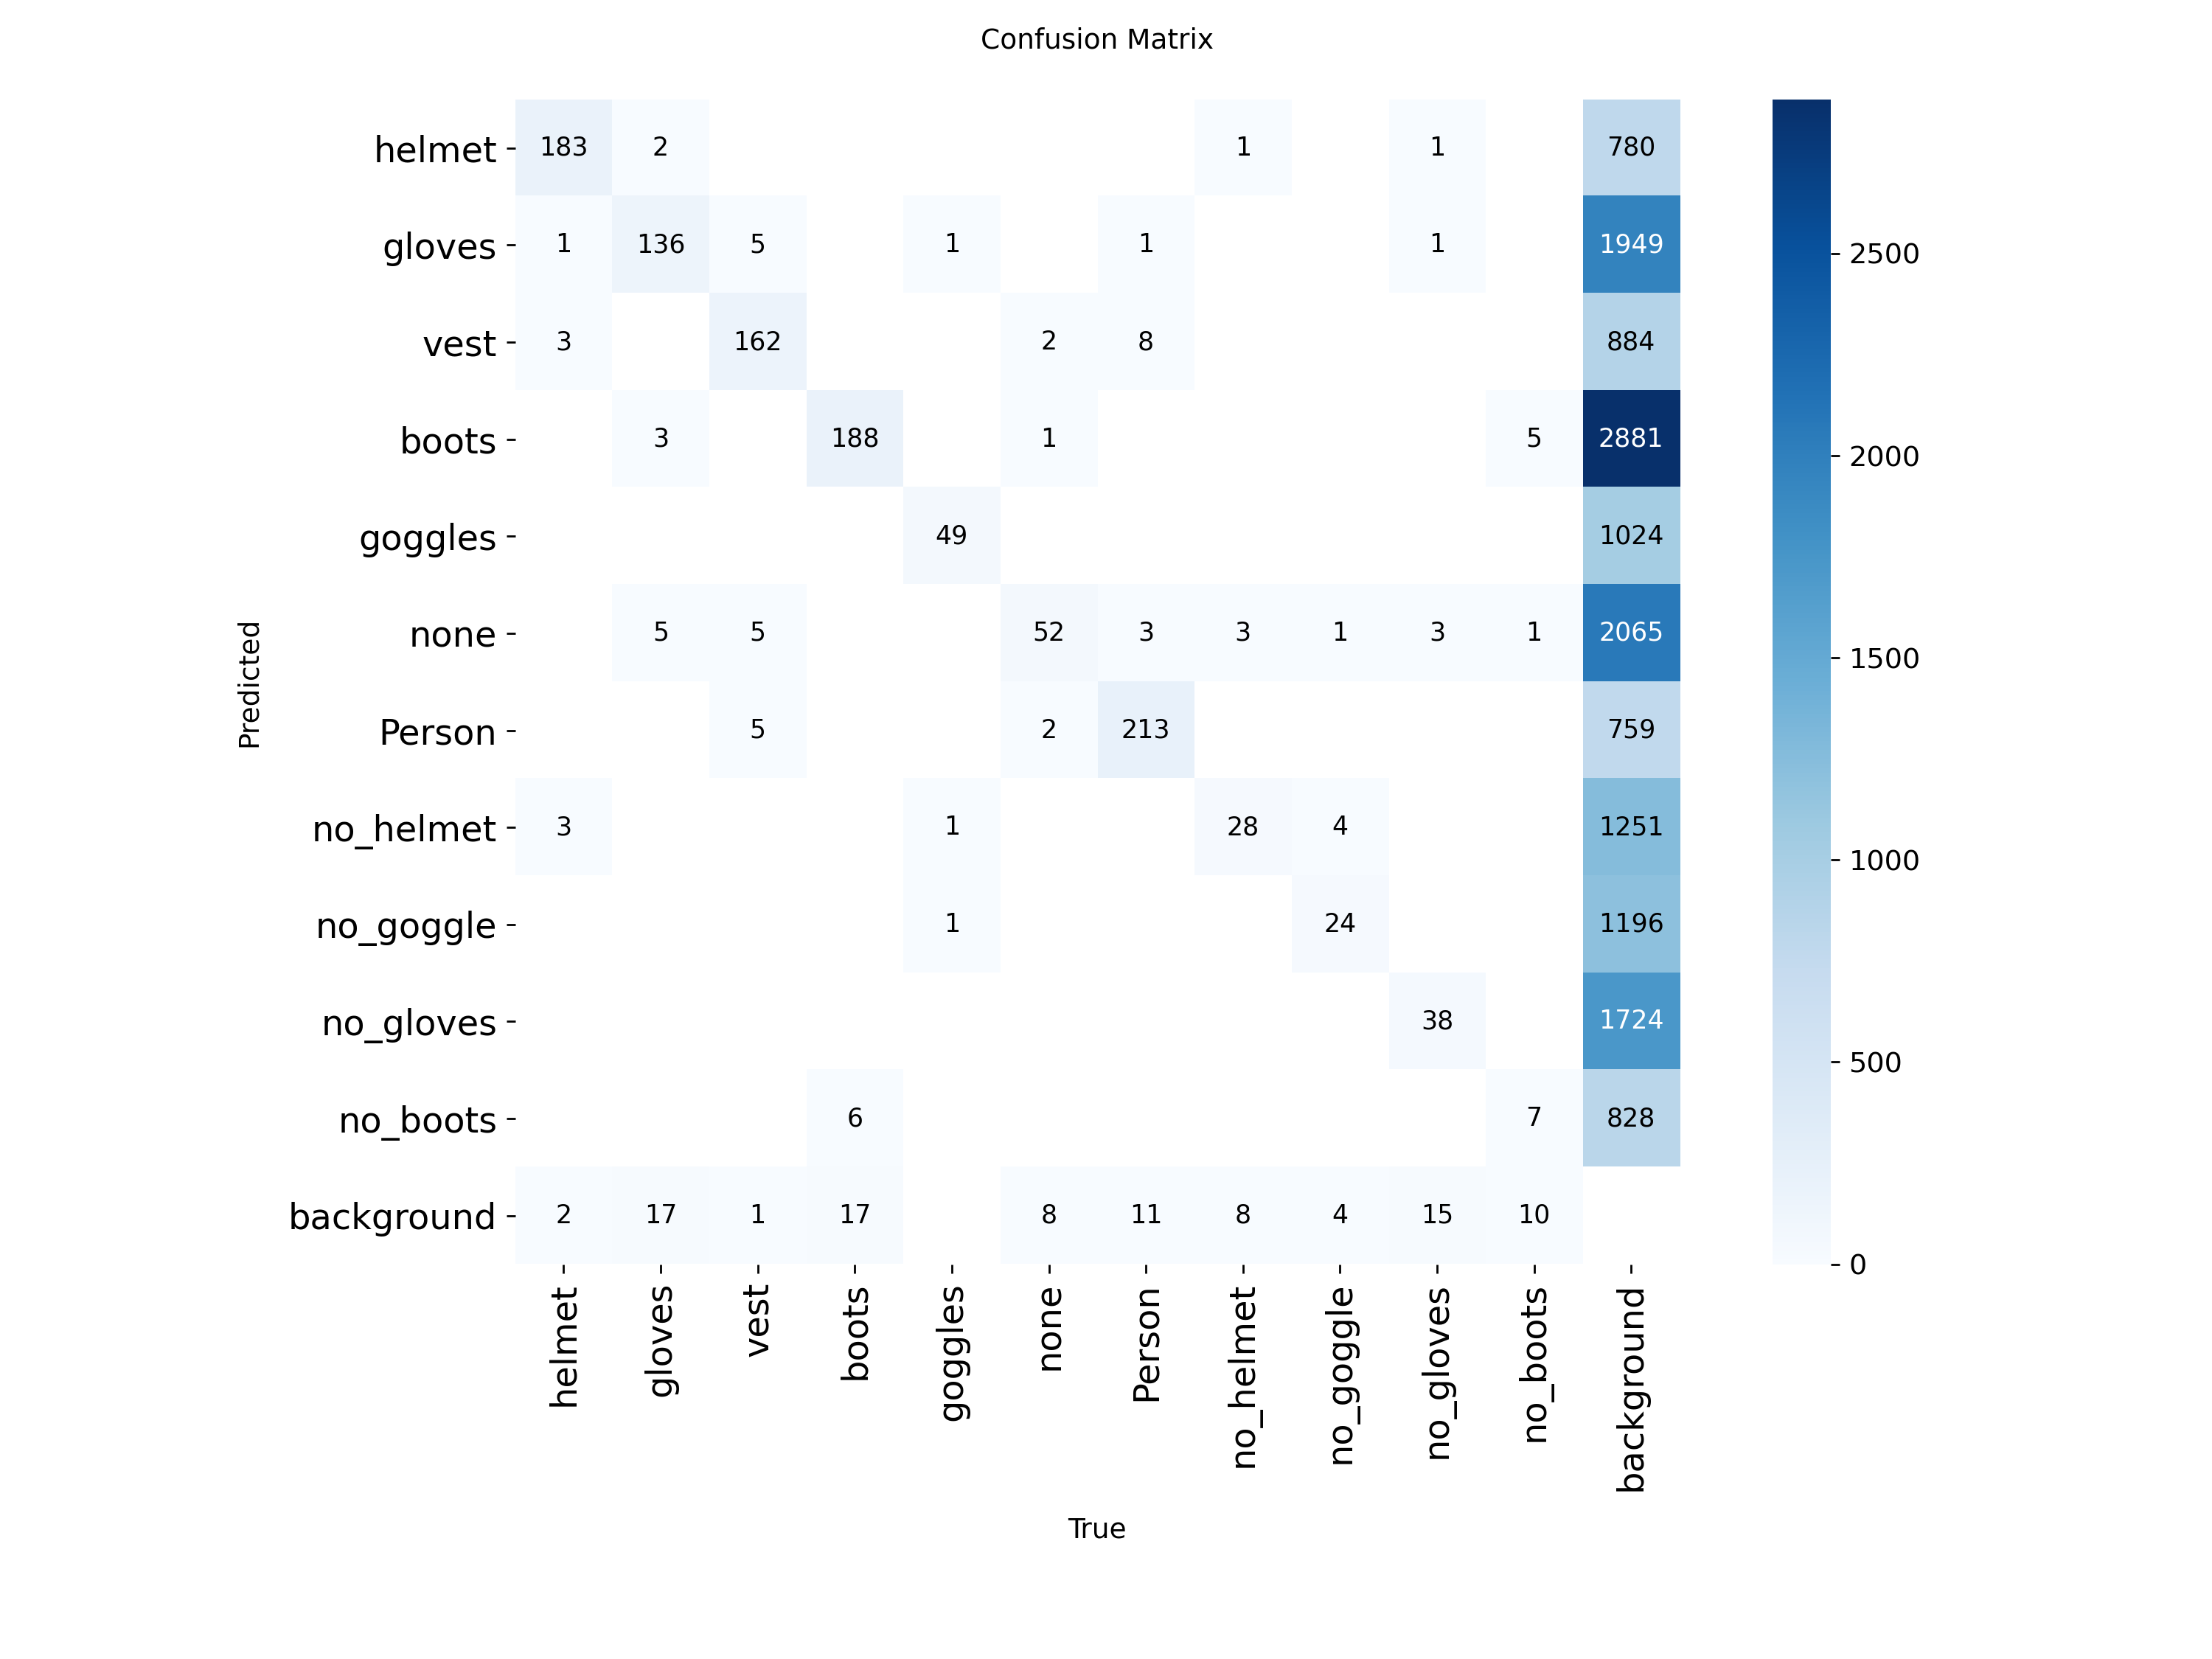

confusion_matrix_normalized.png


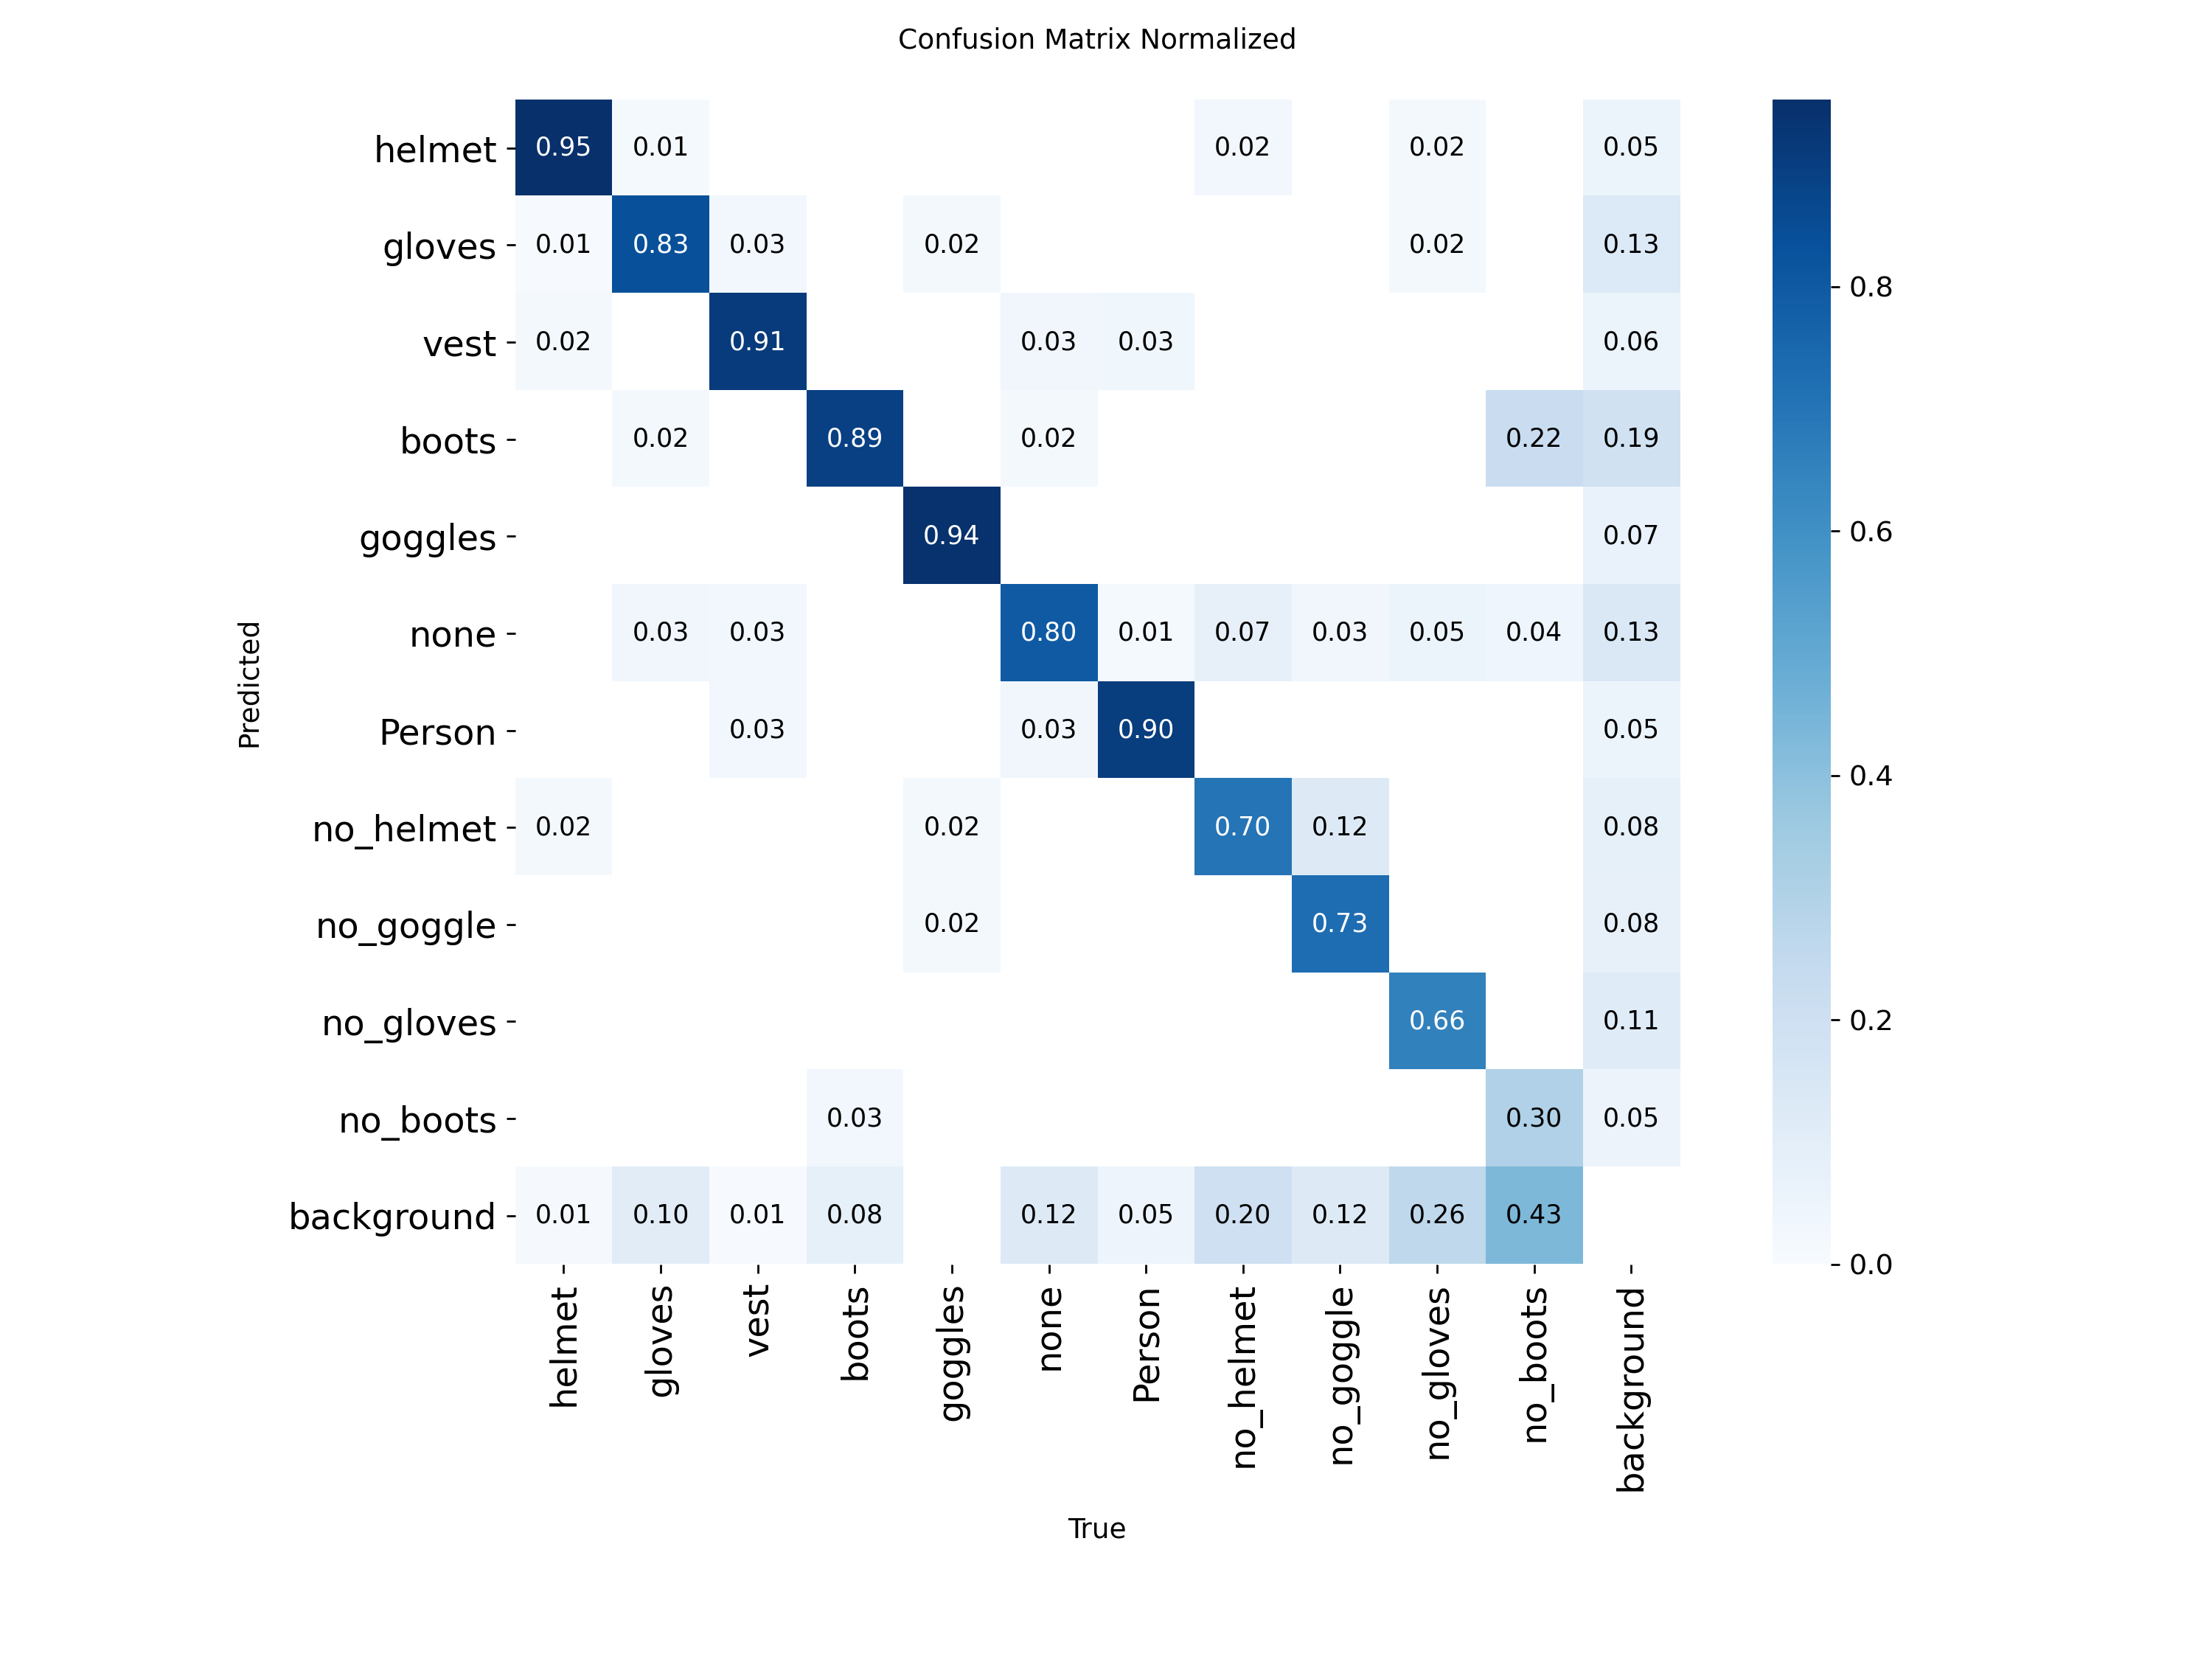

Not found: PR_curve.png
Not found: F1_curve.png
Not found: P_curve.png
Not found: R_curve.png
Not found: results.png


In [ ]:

from pathlib import Path
from IPython.display import display, Image

folder = Path("/content/SmartBuildAI/improved_test_plots")

plot_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "results.png"
]

for name in plot_names:
    path = folder / name

    if path.exists():
        print(name)
        display(Image(filename=str(path), width=650))
    else:
        print("Not found:", name)


In [ ]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/SmartBuildAI")
csv_path = PROJECT_DIR / "safety_detection_report.csv"

df = pd.read_csv(csv_path)

# Summarize detections by class
summary = (
    df.groupby("Detected_class")
    .agg(
        Detection_Count=("Detected_class", "size"),
        Average_Confidence=("Confidence", "mean")
    )
    .round(3)
    .sort_values("Detection_Count", ascending=False)
)

print("SMARTBUILD AI - DETECTION SUMMARY")
print(summary)

# Save summary
summary.to_csv(PROJECT_DIR / "safety_summary.csv")

print("\nSaved:", PROJECT_DIR / "safety_summary.csv")


SMARTBUILD AI - DETECTION SUMMARY
                Detection_Count  Average_Confidence
Detected_class                                     
vest                         64               0.536
Person                       51               0.533
helmet                       26               0.482

Saved: /content/SmartBuildAI/safety_summary.csv


## 17. Generate Possible Missing-PPE Alerts

In [ ]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/SmartBuildAI")
INPUT_CSV = PROJECT_DIR / "safety_detection_report.csv"

df = pd.read_csv(INPUT_CSV)

# PPE classes that indicate possible missing protective equipment
missing_ppe_classes = {
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots",
    "no_vest"
}

alerts = df[df["Detected_class"].isin(missing_ppe_classes)].copy()

if not alerts.empty:
    alerts["Review_Status"] = "Requires human verification"
    alerts["Alert_Level"] = alerts["Confidence"].apply(
        lambda c: "High review priority" if c >= 0.70
        else "Standard review priority"
    )
else:
    alerts = pd.DataFrame(columns=[
        "Timestamp_seconds",
        "Detected_class",
        "Confidence",
        "Review_Status",
        "Alert_Level"
    ])

OUTPUT_CSV = PROJECT_DIR / "safety_alerts.csv"
alerts.to_csv(OUTPUT_CSV, index=False)

print("SMARTBUILD AI - SAFETY REVIEW REPORT")
print("Possible missing-PPE detections:", len(alerts))
print("\n", alerts.head(20).to_string(index=False))
print("\nSaved to:", OUTPUT_CSV)


SMARTBUILD AI - SAFETY REVIEW REPORT
Possible missing-PPE detections: 0

 Empty DataFrame
Columns: [Timestamp_seconds, Detected_class, Confidence, Review_Status, Alert_Level]
Index: []

Saved to: /content/SmartBuildAI/safety_alerts.csv


## 18. Export Project Results to a ZIP File

In [ ]:

from pathlib import Path
import zipfile

PROJECT_DIR = Path("/content/SmartBuildAI")
ZIP_PATH = Path("/content/SmartBuildAI_results.zip")

files_to_export = [
    PROJECT_DIR / "improved_model/weights/best.pt",
    PROJECT_DIR / "baseline/weights/best.pt",
    PROJECT_DIR / "smartbuild_output.mp4",
    PROJECT_DIR / "safety_detection_report.csv",
    PROJECT_DIR / "safety_summary.csv",
    PROJECT_DIR / "safety_alerts.csv"
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in files_to_export:
        if file.exists():
            zf.write(file, arcname=str(file.relative_to(PROJECT_DIR)))
            print("Added:", file.name)
        else:
            print("Skipped (not found):", file.name)

print("\nZIP created:", ZIP_PATH)

from google.colab import files
files.download(str(ZIP_PATH))


Added: best.pt
Added: best.pt
Added: smartbuild_output.mp4
Added: safety_detection_report.csv
Added: safety_summary.csv
Added: safety_alerts.csv

ZIP created: /content/SmartBuildAI_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19.Streamlit Dashboard Setup


In [ ]:

!pip install -q streamlit ultralytics opencv-python-headless pandas matplotlib


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving SmartBuildAI_Streamlit_Dashboard.zip to SmartBuildAI_Streamlit_Dashboard.zip


In [ ]:

import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/SmartBuildAI_Streamlit_Dashboard.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall("/content")

APP_DIR = Path("/content/SmartBuildAI_Streamlit_Dashboard")

print("Dashboard folder:", APP_DIR)
print("Files:", [p.name for p in APP_DIR.iterdir()])


Dashboard folder: /content/SmartBuildAI_Streamlit_Dashboard
Files: ['README.md', 'app.py', 'requirements.txt']


## 20. Verify the Trained Model Path

In [ ]:

from pathlib import Path

model_path = Path(
    "/content/SmartBuildAI/improved_model/weights/best.pt"
)

print("Model found:", model_path.exists())


Model found: True


In [ ]:

%cd /content/SmartBuildAI_Streamlit_Dashboard
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &


/content/SmartBuildAI_Streamlit_Dashboard


## 21. Install pyngrok

In [ ]:

!pip -q install pyngrok


## 22. Configure ngrok and Open the Dashboard

In [ ]:

from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter your ngrok auth token: ")
ngrok.set_auth_token(token)

public_url = ngrok.connect(8501, "http")
print("SmartBuild AI Dashboard:", public_url)


Enter your ngrok auth token: ··········
SmartBuild AI Dashboard: NgrokTunnel: "https://sneer-jersey-calorie.ngrok-free.dev" -> "http://localhost:8501"
